# Volatility Surface Modeling & Options Analytics
## Real-Market Data Edition — SPY Options

---

## 1. Introduction & Setup

### Options Pricing Theory — Overview

An **equity option** gives its holder the right, but not the obligation, to buy (call) or sell (put) an underlying asset at a pre-agreed strike price $K$ on or before an expiry date $T$.

The **Black-Scholes-Merton (BSM)** framework (1973) values European options under several idealized assumptions:

| Assumption | Reality |
|---|---|
| Constant volatility $\sigma$ | Volatility varies with strike and maturity |
| Log-normal returns | Fat tails, skew |
| No transaction costs | Bid-ask spreads, commissions |
| Continuous trading | Discrete rebalancing |
| Constant risk-free rate $r$ | Term structure of rates |

Because realized return distributions exhibit **fat tails** and **negative skewness**, the market prices options at different implied volatilities across strikes and maturities, producing the **volatility surface** — a 2-D manifold $\sigma_{\text{imp}}(K, T)$ that encodes the market's risk-neutral density.

### The SPY Volatility Surface

**SPY** (the SPDR S&P 500 ETF Trust) is one of the most liquid options markets in the world, with thousands of contracts traded daily across dozens of expirations. Its options surface exhibits the classic **equity-index characteristics**:

* **Steep Negative Skew ("Smirk")**: OTM puts carry substantially higher implied vol than OTM calls, driven by institutional demand for downside protection (portfolio insurance) and the leverage effect (declining prices → rising vol).
* **Term-Structure Effects**: The very front of the curve can carry elevated IV (event risk, near-term uncertainty), while in calm markets longer-dated IV usually sits above short-dated IV (an upward-sloping curve).
* **Smile Curvature**: In stressed markets, the smile steepens — both wings rise as demand for tail protection increases.

This notebook pulls **real SPY options data** via `yfinance`, extracts implied volatilities, fits industry-standard parametric models (**SVI** and **SABR**), analyzes Greeks surfaces, simulates **delta hedging** on price paths calibrated to SPY's realized volatility, and detects mispricings — all from first principles.

> **Note**: If `yfinance` is unavailable (no internet, API blocked), the notebook automatically falls back to realistic synthetic data so all analysis runs regardless.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import norm
from scipy.optimize import minimize, brentq, curve_fit
from scipy.interpolate import griddata
from datetime import datetime
import warnings

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(42)

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("ggplot")

pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.6f}".format)
print("All imports OK.")

All imports OK.


In [2]:
USE_REAL_DATA = False

try:
    import yfinance as yf

    spy = yf.Ticker("SPY")

    hist = spy.history(period="5d")
    if len(hist) == 0:
        raise ConnectionError("Could not retrieve SPY price data")
    S0 = float(hist['Close'].iloc[-1])

    expirations = spy.options
    if len(expirations) == 0:
        raise ValueError("No option expirations returned")

    today = datetime.now()
    exp_dates = [datetime.strptime(e, "%Y-%m-%d") for e in expirations]
    days_to_exp = [(e - today).days for e in exp_dates]

    valid_exps = [(e, d) for e, d in zip(expirations, days_to_exp) if 7 <= d <= 730]

    if len(valid_exps) < 5:
        raise ValueError(f"Only {len(valid_exps)} valid expirations found — need at least 5")

    selected_exps = []
    if len(valid_exps) <= 10:
        selected_exps = [e for e, d in valid_exps]
    else:
        indices = np.linspace(0, len(valid_exps) - 1, 10, dtype=int)
        selected_exps = [valid_exps[i][0] for i in indices]

    print(f"SPY spot price: ${S0:.2f}")
    print(f"Selected {len(selected_exps)} expirations: {selected_exps}")

    all_calls = []
    all_puts = []
    for exp in selected_exps:
        try:
            chain = spy.option_chain(exp)
            calls_df = chain.calls.copy()
            calls_df['expiration'] = exp
            puts_df = chain.puts.copy()
            puts_df['expiration'] = exp
            all_calls.append(calls_df)
            all_puts.append(puts_df)
        except Exception as e_chain:
            print(f"  ⚠️ Skipping {exp}: {e_chain}")

    if len(all_calls) < 3:
        raise ValueError("Fewer than 3 expiration chains retrieved")

    calls_raw = pd.concat(all_calls, ignore_index=True)
    puts_raw = pd.concat(all_puts, ignore_index=True)

    try:
        tnx = yf.Ticker("^TNX")
        tnx_hist = tnx.history(period="5d")
        r = float(tnx_hist['Close'].iloc[-1]) / 100.0
    except Exception:
        r = 0.045

    q = 0.013

    for df_raw, label in [(calls_raw, "calls"), (puts_raw, "puts")]:
        print(f"  Raw {label}: {len(df_raw)} rows")

    calls_clean = calls_raw[
        (calls_raw['volume'].fillna(0) > 0) &
        (calls_raw['openInterest'].fillna(0) > 10) &
        (calls_raw['bid'].fillna(0) > 0) &
        (calls_raw['ask'].fillna(0) > 0)
    ].copy()

    puts_clean = puts_raw[
        (puts_raw['volume'].fillna(0) > 0) &
        (puts_raw['openInterest'].fillna(0) > 10) &
        (puts_raw['bid'].fillna(0) > 0) &
        (puts_raw['ask'].fillna(0) > 0)
    ].copy()

    calls_clean['mid_price'] = (calls_clean['bid'] + calls_clean['ask']) / 2
    puts_clean['mid_price'] = (puts_clean['bid'] + puts_clean['ask']) / 2

    today_dt = pd.Timestamp.now()
    calls_clean['T'] = (pd.to_datetime(calls_clean['expiration']) - today_dt).dt.days / 365.25
    puts_clean['T'] = (pd.to_datetime(puts_clean['expiration']) - today_dt).dt.days / 365.25

    calls_clean = calls_clean[
        (calls_clean['strike'] >= S0 * 0.80) &
        (calls_clean['strike'] <= S0 * 1.20)
    ].copy()
    puts_clean = puts_clean[
        (puts_clean['strike'] >= S0 * 0.80) &
        (puts_clean['strike'] <= S0 * 1.20)
    ].copy()

    calls_clean['moneyness'] = calls_clean['strike'] / S0
    puts_clean['moneyness'] = puts_clean['strike'] / S0

    print(f"\n✅ Real data loaded successfully!")
    print(f"  Spot: ${S0:.2f} | Risk-free rate: {r:.4f} | Div yield: {q:.4f}")
    print(f"  Clean calls: {len(calls_clean):,} | Clean puts: {len(puts_clean):,}")
    print(f"  Expirations: {calls_clean['expiration'].nunique()}")
    print(f"  Strike range: ${calls_clean['strike'].min():.0f} – ${calls_clean['strike'].max():.0f}")

    USE_REAL_DATA = True

except Exception as e:
    print(f"⚠️  Could not load real market data: {e}")
    print("    Falling back to synthetic options data...\n")
    USE_REAL_DATA = False
    S0 = 100.0
    r  = 0.05
    q  = 0.02

print(f"\nData source: {'REAL SPY options (yfinance)' if USE_REAL_DATA else 'Synthetic (generated)'}")
print(f"Spot = ${S0:.2f}  |  r = {r:.4f}  |  q = {q:.4f}")

SPY spot price: $769.05
Selected 10 expirations: ['2026-10-29', '2026-11-06', '2026-11-20', '2026-12-18', '2027-01-15', '2027-02-19', '2027-03-31', '2027-06-30', '2027-09-30', '2028-06-16']


  Raw calls: 1630 rows
  Raw puts: 1567 rows

✅ Real data loaded successfully!
  Spot: $769.05 | Risk-free rate: 0.0512 | Div yield: 0.0130
  Clean calls: 753 | Clean puts: 746
  Expirations: 10
  Strike range: $620 – $920

Data source: REAL SPY options (yfinance)
Spot = $769.05  |  r = 0.0512  |  q = 0.0130


---
## 2. Black-Scholes Framework

### 2.1 Black-Scholes Formula

For a European **call** on a dividend-paying stock:

$$
C = S\,e^{-qT}\,N(d_1) \;-\; K\,e^{-rT}\,N(d_2)
$$

For a European **put**:

$$
P = K\,e^{-rT}\,N(-d_2) \;-\; S\,e^{-qT}\,N(-d_1)
$$

where

$$
d_1 = \frac{\ln(S/K) + \left(r - q + \tfrac{1}{2}\sigma^2\right)T}{\sigma\sqrt{T}}, \qquad
d_2 = d_1 - \sigma\sqrt{T}
$$

and $N(\cdot)$ is the standard-normal CDF.


In [3]:
def bs_price(S, K, T, r, q, sigma, option_type="call"):
    '''Black-Scholes European option price (vectorised).'''
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if option_type == "call":
        return S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    else:
        return K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)


def bs_implied_vol(market_price, S, K, T, r, q, option_type="call",
                   tol=1e-8, max_iter=200):
    '''Extract implied vol via Brent method with robust bracketing.'''
    intrinsic = max(S * np.exp(-q * T) - K * np.exp(-r * T), 0.0) if option_type == "call" \
                else max(K * np.exp(-r * T) - S * np.exp(-q * T), 0.0)
    if market_price <= intrinsic + 1e-10:
        return np.nan
    if T < 1e-6:
        return np.nan

    def objective(sigma):
        return bs_price(S, K, T, r, q, sigma, option_type) - market_price

    try:
        return brentq(objective, 1e-4, 5.0, xtol=tol, maxiter=max_iter)
    except (ValueError, RuntimeError):
        return np.nan


price = bs_price(S0, S0, 0.25, r, q, 0.20, "call")
iv = bs_implied_vol(price, S0, S0, 0.25, r, q, "call")
print(f"BS call price (ATM, T=0.25, σ=0.20): {price:.4f}")
print(f"Round-trip implied vol:               {iv:.6f}")

BS call price (ATM, T=0.25, σ=0.20): 34.2015
Round-trip implied vol:               0.200000


### 2.2 Analytical Greeks

| Greek | Formula (Call) |
|---|---|
| **Delta** | $\Delta = e^{-qT}\,N(d_1)$ |
| **Gamma** | $\Gamma = \dfrac{e^{-qT}\,n(d_1)}{S\,\sigma\sqrt{T}}$ |
| **Theta** | $\Theta = -\dfrac{S\,\sigma\,e^{-qT}\,n(d_1)}{2\sqrt{T}} - rKe^{-rT}N(d_2) + qSe^{-qT}N(d_1)$ |
| **Vega** | $\mathcal{V} = S\,e^{-qT}\,\sqrt{T}\,n(d_1)$ |
| **Rho** | $\rho = K\,T\,e^{-rT}\,N(d_2)$ |

where $n(\cdot)$ is the standard-normal PDF.


In [4]:
def bs_greeks(S, K, T, r, q, sigma, option_type="call"):
    '''Return a dict of all Black-Scholes Greeks.'''
    if T < 1e-8:
        T = 1e-8
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    n_d1 = norm.pdf(d1)
    N_d1 = norm.cdf(d1)
    N_d2 = norm.cdf(d2)
    disc_S = np.exp(-q * T)
    disc_K = np.exp(-r * T)

    if option_type == "call":
        delta = disc_S * N_d1
        theta = (-S * sigma * disc_S * n_d1 / (2 * np.sqrt(T))
                 - r * K * disc_K * N_d2
                 + q * S * disc_S * N_d1)
        rho   = K * T * disc_K * N_d2
    else:
        delta = -disc_S * norm.cdf(-d1)
        theta = (-S * sigma * disc_S * n_d1 / (2 * np.sqrt(T))
                 + r * K * disc_K * norm.cdf(-d2)
                 - q * S * disc_S * norm.cdf(-d1))
        rho   = -K * T * disc_K * norm.cdf(-d2)

    gamma = disc_S * n_d1 / (S * sigma * np.sqrt(T))
    vega  = S * disc_S * np.sqrt(T) * n_d1

    return {"delta": delta, "gamma": gamma, "theta": theta,
            "vega": vega, "rho": rho}

g = bs_greeks(S0, S0, 0.25, r, q, 0.20, "call")
for name, val in g.items():
    print(f"  {name:>6s} = {val:+.6f}")

   delta = +0.556002
   gamma = +0.005116
   theta = -75.090030
    vega = +151.297189
     rho = +98.348023


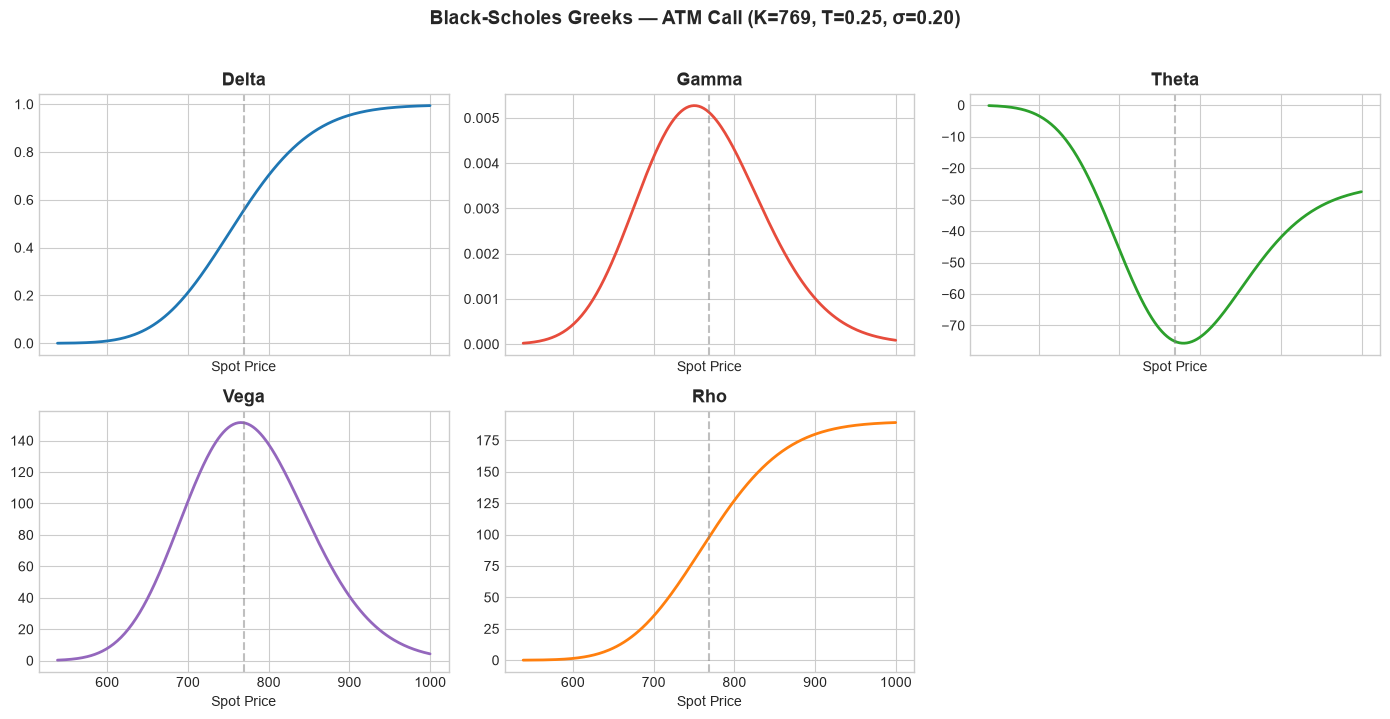

In [5]:
spots = np.linspace(S0 * 0.7, S0 * 1.3, 300)
K_atm, T_atm, sigma_atm = S0, 0.25, 0.20

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
greek_names = ["delta", "gamma", "theta", "vega", "rho"]
colors = ["#1f77b4", "#e74c3c", "#2ca02c", "#9467bd", "#ff7f0e"]

for idx, (name, color) in enumerate(zip(greek_names, colors)):
    ax = axes.flat[idx]
    vals = [bs_greeks(s, K_atm, T_atm, r, q, sigma_atm, "call")[name] for s in spots]
    ax.plot(spots, vals, color=color, lw=2)
    ax.axvline(K_atm, ls="--", color="grey", alpha=0.5)
    ax.set_title(name.capitalize(), fontsize=13, fontweight="bold")
    ax.set_xlabel("Spot Price")

axes.flat[-1].set_visible(False)
fig.suptitle(f"Black-Scholes Greeks — ATM Call (K={K_atm:.0f}, T=0.25, σ=0.20)",
             fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout()
plt.show()

---
## 3. Options Chain Construction

### Real Data Path (SPY via yfinance)
When real data is available, the notebook uses the **live SPY options chain** — mid-prices from actual bid/ask quotes across multiple expirations. The data is filtered for liquidity (volume > 0, open interest > 10) and moneyness (strikes within ±20% of spot).

### Synthetic Fallback
If `yfinance` is unavailable, a realistic synthetic chain is generated using a parametric volatility surface that embeds equity-index-style features:
- **Skew**: vol rises for low strikes
- **Smile curvature**: slight uptick in the wings
- **Term-structure decay**: short-dated vol is elevated


In [6]:
if USE_REAL_DATA:
    rows = []
    for _, row in calls_clean.iterrows():
        rows.append({
            "strike": row["strike"],
            "maturity": row["T"],
            "expiration": row["expiration"],
            "option_type": "call",
            "market_price": row["mid_price"],
            "moneyness": row["moneyness"],
            "volume": row.get("volume", 0),
            "openInterest": row.get("openInterest", 0),
        })
    for _, row in puts_clean.iterrows():
        rows.append({
            "strike": row["strike"],
            "maturity": row["T"],
            "expiration": row["expiration"],
            "option_type": "put",
            "market_price": row["mid_price"],
            "moneyness": row["moneyness"],
            "volume": row.get("volume", 0),
            "openInterest": row.get("openInterest", 0),
        })

    options_df = pd.DataFrame(rows)

    unique_T = sorted(options_df['maturity'].unique())
    maturity_years = np.array(unique_T)
    maturity_labels = [f"{int(round(t * 365.25))}d" for t in maturity_years]

    t_to_label = dict(zip(maturity_years, maturity_labels))
    options_df['mat_label'] = options_df['maturity'].map(t_to_label)

    strikes = np.sort(options_df['strike'].unique())

    print(f"Real options chain: {len(options_df):,} rows")
    print(f"  {len(strikes)} unique strikes × {len(maturity_years)} expirations")
    print(f"  Maturities: {maturity_labels}")

else:
    maturity_labels = ["1w", "2w", "1m", "2m", "3m", "6m", "9m", "1y", "2y"]
    maturity_years  = np.array([1/52, 2/52, 1/12, 2/12, 3/12, 6/12, 9/12, 1.0, 2.0])
    t_to_label = dict(zip(maturity_years, maturity_labels))

    strikes = np.arange(S0 * 0.70, S0 * 1.31, S0 * 0.02)

    def true_vol_surface(K, T, S=S0, seed=42):
        '''Parametric vol surface embedding skew, smile, and term structure.'''
        rng = np.random.default_rng(seed)
        moneyness = K / S
        base      = 0.20
        skew      = 0.10 * (1.0 - moneyness) / np.sqrt(np.maximum(T, 1e-4))
        curvature = 0.06 * (1.0 - moneyness)**2
        term      = 0.03 * np.exp(-2.0 * T)
        noise     = rng.normal(0, 0.003, size=np.broadcast_shapes(np.shape(K), np.shape(T)))
        sigma     = base + skew + curvature + term + noise
        return np.clip(sigma, 0.05, 1.0)

    K_grid, T_grid = np.meshgrid(strikes, maturity_years)
    vol_grid = true_vol_surface(K_grid, T_grid)

    rows = []
    for i, (T_val, T_label) in enumerate(zip(maturity_years, maturity_labels)):
        for j, K_val in enumerate(strikes):
            sigma_true = float(vol_grid[i, j])
            for otype in ["call", "put"]:
                price_exact = bs_price(S0, K_val, T_val, r, q, sigma_true, otype)
                vega = bs_greeks(S0, K_val, T_val, r, q, sigma_true, otype)["vega"]
                price_noise = np.random.normal(0, 0.003) * max(vega, 0.01)
                price_mkt = max(price_exact + price_noise, 1e-6)
                rows.append({
                    "strike": K_val,
                    "maturity": T_val,
                    "mat_label": T_label,
                    "option_type": otype,
                    "true_vol": sigma_true,
                    "market_price": price_mkt,
                    "moneyness": K_val / S0,
                })

    options_df = pd.DataFrame(rows)
    print(f"Synthetic options chain: {len(options_df):,} rows  |  "
          f"{options_df['strike'].nunique()} strikes × "
          f"{options_df['maturity'].nunique()} maturities × 2 types")

Real options chain: 1,499 rows
  212 unique strikes × 10 expirations
  Maturities: ['7d', '15d', '29d', '57d', '85d', '120d', '160d', '251d', '343d', '603d']


In [7]:
sample = options_df[options_df["option_type"] == "call"].copy()

if USE_REAL_DATA:
    print(f"Sample of call options (top rows):\n")
    display(sample[['strike', 'maturity', 'mat_label', 'market_price', 'moneyness']].head(15).round(4))
else:
    sample_piv = sample.pivot_table(
        index="strike", columns="mat_label", values="true_vol", aggfunc="first"
    )[maturity_labels]
    sample_piv.index.name = "Strike"
    print("True implied-vol surface (calls only, sample):\n")
    display(sample_piv.iloc[::5].round(4))

Sample of call options (top rows):



,strike,maturity,mat_label,market_price,moneyness
0,760.000000,0.019200,7d,13.645000,0.988200
1,761.000000,0.019200,7d,12.880000,0.989500
2,762.000000,0.019200,7d,12.125000,0.990800
3,763.000000,0.019200,7d,11.360000,0.992100
4,764.000000,0.019200,7d,10.640000,0.993400
5,765.000000,0.019200,7d,9.950000,0.994700
6,766.000000,0.019200,7d,9.250000,0.996000
7,767.000000,0.019200,7d,8.585000,0.997300
8,768.000000,0.019200,7d,7.940000,0.998600
9,769.000000,0.019200,7d,7.305000,0.999900


---
## 4. Implied Volatility Surface Construction

Implied volatilities are extracted from market prices (real mid-prices or synthetic noisy prices) using the `bs_implied_vol` Brent solver from Section 2.

Any quote the solver cannot invert (a price at or below intrinsic value, or an IV outside 1%–200%) is dropped. Because the chain was already filtered for volume, open interest and a ±20% strike band, all **1,499** SPY quotes in this run produced a valid IV, ranging from **11.1% to 56.8%** with a median of **17.8%**.

In [8]:
iv_list = []
for _, row in options_df.iterrows():
    iv = bs_implied_vol(row["market_price"], S0, row["strike"],
                        row["maturity"], r, q, row["option_type"])
    iv_list.append(iv)

options_df["implied_vol"] = iv_list

valid = options_df.dropna(subset=["implied_vol"])
valid = valid[valid["implied_vol"] > 0.01]
valid = valid[valid["implied_vol"] < 2.0]

options_df = options_df[options_df["implied_vol"].notna() &
                        (options_df["implied_vol"] > 0.01) &
                        (options_df["implied_vol"] < 2.0)]

if not USE_REAL_DATA and "true_vol" in valid.columns:
    rmse_rt = np.sqrt(np.mean((valid["implied_vol"] - valid["true_vol"])**2))
    print(f"Round-trip RMSE (implied vol vs true vol): {rmse_rt:.6f}")

print(f"Valid IV extractions: {len(valid):,} / {len(iv_list):,}")
print(f"IV range: {valid['implied_vol'].min():.4f} – {valid['implied_vol'].max():.4f}")
print(f"Median IV: {valid['implied_vol'].median():.4f}")

Valid IV extractions: 1,499 / 1,499
IV range: 0.1108 – 0.5680
Median IV: 0.1775


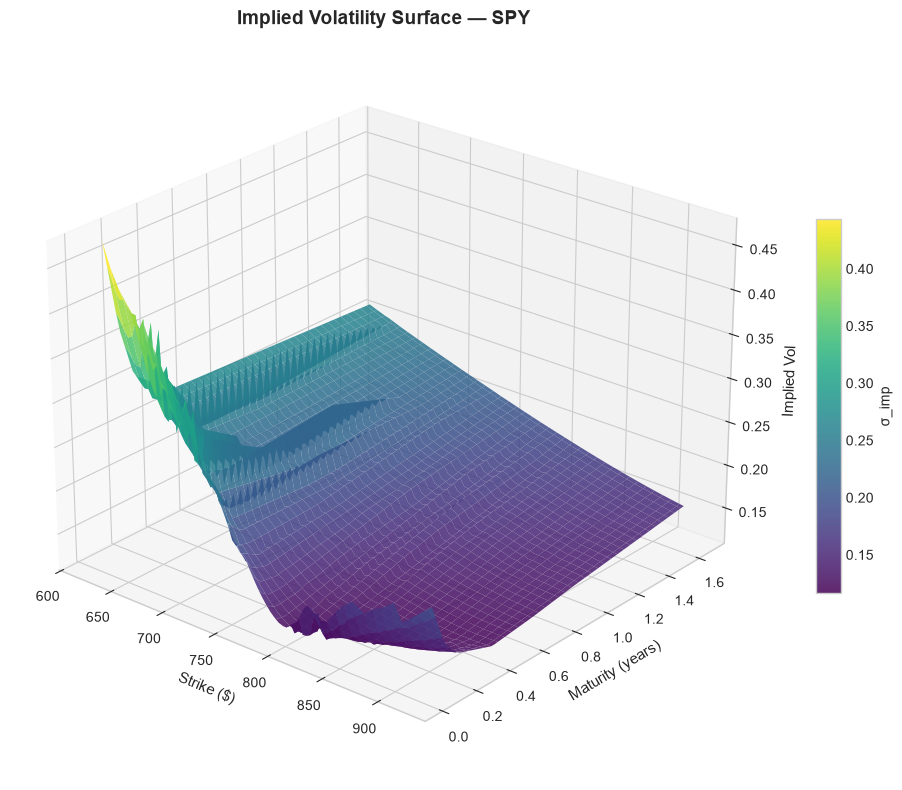

In [9]:
calls = options_df[(options_df["option_type"] == "call") &
                   options_df["implied_vol"].notna()].copy()

fig = plt.figure(figsize=(12, 8))
ax  = fig.add_subplot(111, projection="3d")

X = calls["strike"].values
Y = calls["maturity"].values
Z = calls["implied_vol"].values

xi = np.linspace(X.min(), X.max(), 80)
yi = np.linspace(Y.min(), Y.max(), 80)
XI, YI = np.meshgrid(xi, yi)
ZI = griddata((X, Y), Z, (XI, YI), method="linear")

surf = ax.plot_surface(XI, YI, ZI, cmap=cm.viridis, alpha=0.85,
                       edgecolor="none", antialiased=True)
ax.set_xlabel("Strike ($)", fontsize=11)
ax.set_ylabel("Maturity (years)", fontsize=11)
ax.set_zlabel("Implied Vol", fontsize=11)
data_label = "SPY" if USE_REAL_DATA else "Synthetic"
ax.set_title(f"Implied Volatility Surface — {data_label}", fontsize=14, fontweight="bold")
fig.colorbar(surf, shrink=0.5, aspect=15, label="σ_imp")
ax.view_init(elev=25, azim=-50)
fig.tight_layout()
plt.show()

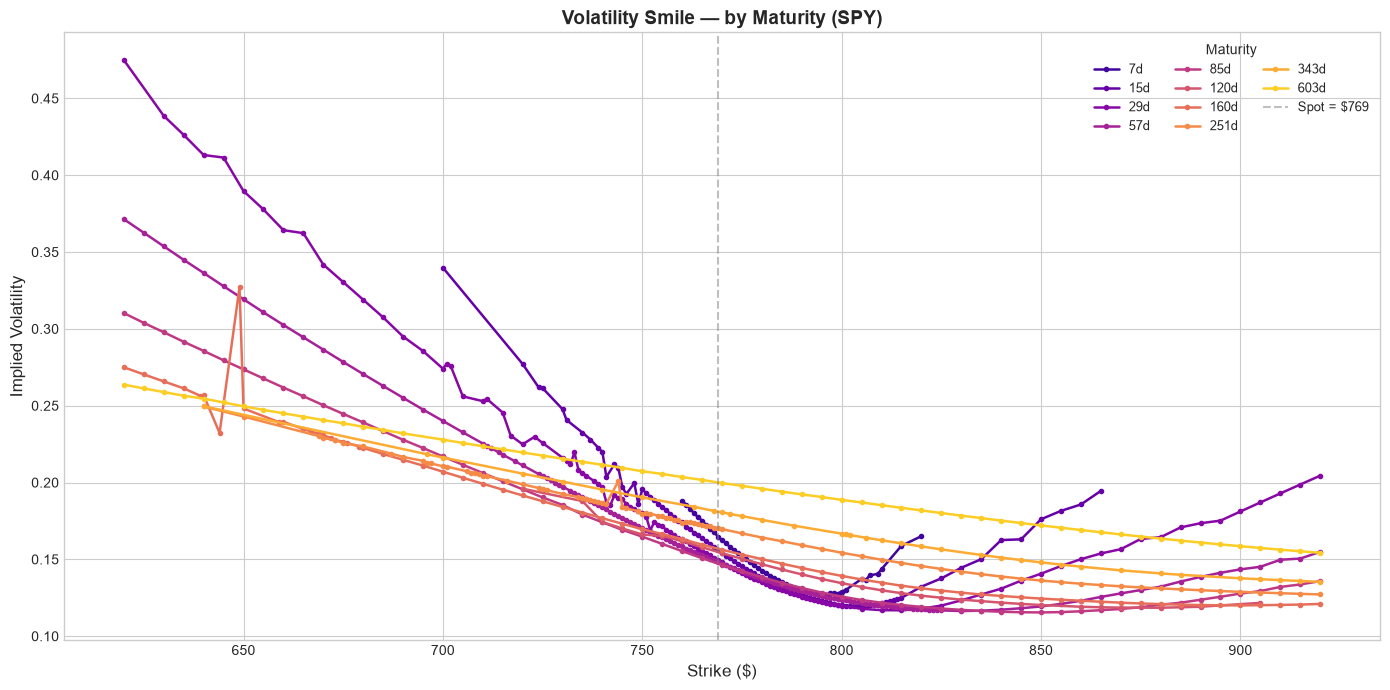

In [10]:
fig, ax = plt.subplots(figsize=(14, 7))
unique_mats = sorted(calls["maturity"].unique())
cmap_colors = cm.plasma(np.linspace(0.1, 0.9, len(unique_mats)))

for idx, T_val in enumerate(unique_mats):
    mask = (calls["maturity"] == T_val)
    sub  = calls[mask].sort_values("strike")
    if len(sub) < 3:
        continue
    label = t_to_label.get(T_val, f"{T_val:.3f}y")
    ax.plot(sub["strike"], sub["implied_vol"], marker="o", ms=3,
            lw=1.8, color=cmap_colors[idx], label=label)

ax.axvline(S0, ls="--", color="grey", alpha=0.5, label=f"Spot = ${S0:.0f}")
ax.set_xlabel("Strike ($)", fontsize=12)
ax.set_ylabel("Implied Volatility", fontsize=12)
data_label = "SPY" if USE_REAL_DATA else "Synthetic"
ax.set_title(f"Volatility Smile — by Maturity ({data_label})", fontsize=14, fontweight="bold")
ax.legend(title="Maturity", ncol=3, fontsize=9)
fig.tight_layout()
plt.show()

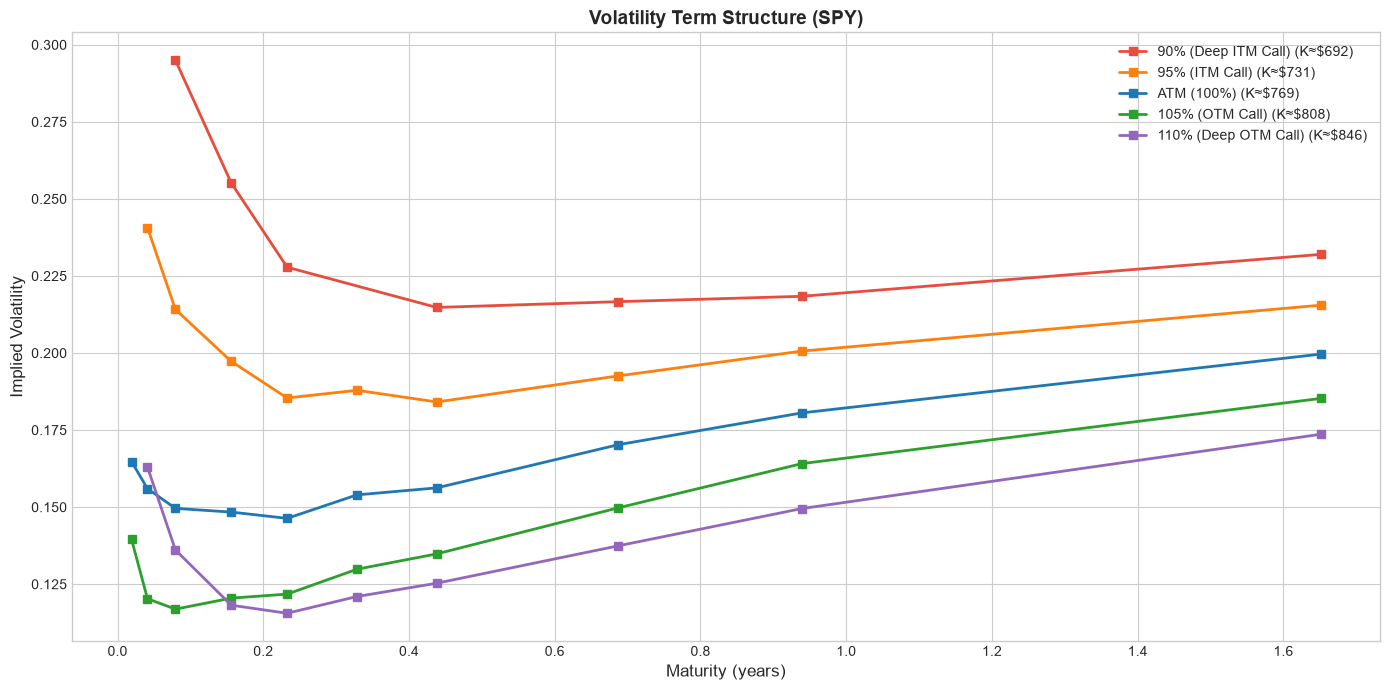

In [11]:
fig, ax = plt.subplots(figsize=(14, 7))
moneyness_targets = [0.90, 0.95, 1.00, 1.05, 1.10]
colors_ts = ["#e74c3c", "#ff7f0e", "#1f77b4", "#2ca02c", "#9467bd"]
labels_ts = ["90% (Deep ITM Call)", "95% (ITM Call)", "ATM (100%)",
             "105% (OTM Call)", "110% (Deep OTM Call)"]

for m, c, lab in zip(moneyness_targets, colors_ts, labels_ts):
    target_K = S0 * m
    pts = []
    for T_val, sub in calls.groupby("maturity"):
        nearest = sub.iloc[(sub["strike"] - target_K).abs().argmin()]
        if abs(nearest["strike"] - target_K) <= 0.01 * S0:
            pts.append((T_val, nearest["implied_vol"]))
    if len(pts) >= 2:
        T_pts, iv_pts = zip(*sorted(pts))
        ax.plot(T_pts, iv_pts, marker="s", ms=6, lw=2, color=c,
                label=f"{lab} (K≈${target_K:.0f})")

ax.set_xlabel("Maturity (years)", fontsize=12)
ax.set_ylabel("Implied Volatility", fontsize=12)
data_label = "SPY" if USE_REAL_DATA else "Synthetic"
ax.set_title(f"Volatility Term Structure ({data_label})", fontsize=14, fontweight="bold")
ax.legend(fontsize=10)
fig.tight_layout()
plt.show()

### Observations

Snapshot used in this run: SPY at **$769.05**, 10 expirations from **7 to 603 days**, strikes **$620–$920**.

* **Steep put skew**: Every maturity shows IV falling as the strike rises. At 29 days, IV is about **47%** at the $620 strike (19% below spot) but only about **12%** near $800–$820.
* **Smile only at the short end**: Expirations up to about 57 days turn back up for out-of-the-money calls (the 29-day slice climbs back to about 20% at $920), so the lowest IV sits above spot rather than at it. From 160 days out, the curves are close to straight downward-sloping lines with little or no call-side upturn.
* **Skew flattens with maturity**: The gap between the 90% and 110% strikes is about **16 vol points** at 29 days (29.5% vs 13.6%) and narrows to about **6 points** at 603 days (23.2% vs 17.4%).
* **Term structure is hockey-stick shaped**: ATM IV slips from 16.5% at 7 days to a low of **14.6% at 85 days**, then rises steadily to **20.0% at 603 days**. ATM and out-of-the-money call strikes turn upward after about three months; the downside strikes (90%–95%) keep falling until about 160 days, then flatten and rise slightly.
* **Noisy quotes**: A few isolated points break the otherwise smooth curves, most visibly the 160-day slice near $644–$649 and the 251-day slice at $744. These deep in-the-money calls have wide bid-ask spreads and show up again in the mispricing scan (Section 10).

---
## 5. SVI (Stochastic Volatility Inspired) Model Fitting

The **SVI parameterisation** (Gatheral, 2004) models the total implied variance $w(k) = \sigma_{\text{BS}}^2\,T$ as a function of log-moneyness $k = \ln(K / F)$:

$$
w(k) = a + b\left[\rho\,(k - m) + \sqrt{(k - m)^2 + \sigma^2}\right]
$$

**Parameters**: $a$ (overall variance level), $b$ (slope of the wings), $\rho$ (rotation / skew), $m$ (translation), $\sigma$ (smoothness of the ATM region).

**No-arbitrage constraints**: $a + b\,\sigma\sqrt{1 - \rho^2} \geq 0$, $b \geq 0$, $|\rho| < 1$, $\sigma > 0$.


In [12]:
def svi_total_variance(k, a, b, rho, m, sigma_svi):
    '''SVI total implied variance w(k).'''
    return a + b * (rho * (k - m) + np.sqrt((k - m)**2 + sigma_svi**2))


def fit_svi_slice(strikes_slice, iv_slice, T, S=S0, r_=r, q_=q):
    '''Fit SVI parameters to one maturity slice.  Returns (params, rmse, iv_fit).'''
    F = S * np.exp((r_ - q_) * T)
    k = np.log(strikes_slice / F)
    w_mkt = iv_slice**2 * T

    def objective(params):
        a, b, rho, m, sig = params
        w_model = svi_total_variance(k, a, b, rho, m, sig)
        arb_gap = max(0.0, -(a + b * sig * np.sqrt(1.0 - rho**2)))
        return np.sum((w_model - w_mkt)**2) + 1e3 * arb_gap**2

    best_res = None
    for a0 in [0.01, 0.04, 0.08]:
        for rho0 in [-0.7, -0.4, -0.1, 0.0]:
            x0 = [a0, 0.1, rho0, 0.0, 0.1]
            bounds = [(-0.5, 2.0), (1e-4, 5.0), (-0.999, 0.999),
                      (-1.0, 1.0), (1e-4, 5.0)]
            try:
                res = minimize(objective, x0, method="L-BFGS-B", bounds=bounds)
                if best_res is None or res.fun < best_res.fun:
                    best_res = res
            except Exception:
                continue

    if best_res is None:
        return None, np.inf, np.full_like(iv_slice, np.nan)

    params = best_res.x
    w_fit  = svi_total_variance(k, *params)
    iv_fit = np.sqrt(np.maximum(w_fit / T, 1e-8))
    rmse   = np.sqrt(np.mean((iv_fit - iv_slice)**2))
    return params, rmse, iv_fit


svi_results = {}
for T_val in sorted(calls["maturity"].unique()):
    mask = (calls["maturity"] == T_val)
    sub  = calls[mask].sort_values("strike")
    if len(sub) < 5:
        continue
    params, rmse, iv_fit = fit_svi_slice(sub["strike"].values,
                                          sub["implied_vol"].values, T_val)
    if params is None:
        continue
    T_label = t_to_label.get(T_val, f"{T_val:.3f}y")
    svi_results[T_label] = {
        "T": T_val, "params": params, "rmse": rmse,
        "strikes": sub["strike"].values,
        "iv_market": sub["implied_vol"].values,
        "iv_fit": iv_fit,
    }
    print(f"  {T_label:>6s}  RMSE={rmse:.6f}  a={params[0]:+.4f}  "
          f"b={params[1]:.4f}  ρ={params[2]:+.4f}  m={params[3]:+.4f}  σ={params[4]:.4f}")

      7d  RMSE=0.003384  a=-0.0052  b=0.0888  ρ=-0.7028  m=-0.0587  σ=0.0878
     15d  RMSE=0.003685  a=-0.0059  b=0.0596  ρ=-0.4038  m=-0.0152  σ=0.1202


     29d  RMSE=0.003682  a=-0.0878  b=0.2165  ρ=-0.4057  m=-0.1425  σ=0.4492


     57d  RMSE=0.000952  a=-0.0158  b=0.1015  ρ=-0.4283  m=-0.0213  σ=0.1956
     85d  RMSE=0.000890  a=-0.0318  b=0.1263  ρ=-0.1508  m=+0.0452  σ=0.2791


    120d  RMSE=0.001488  a=-0.0016  b=0.0726  ρ=-0.7029  m=-0.0021  σ=0.1214


    160d  RMSE=0.009661  a=-0.0203  b=0.1218  ρ=-0.4253  m=+0.0106  σ=0.2416
    251d  RMSE=0.001791  a=+0.0036  b=0.0834  ρ=-0.7044  m=+0.0444  σ=0.1274


    343d  RMSE=0.000154  a=-0.0190  b=0.1705  ρ=-0.1305  m=+0.1288  σ=0.2144
    603d  RMSE=0.000121  a=-0.0775  b=0.2909  ρ=-0.0564  m=+0.2268  σ=0.3791


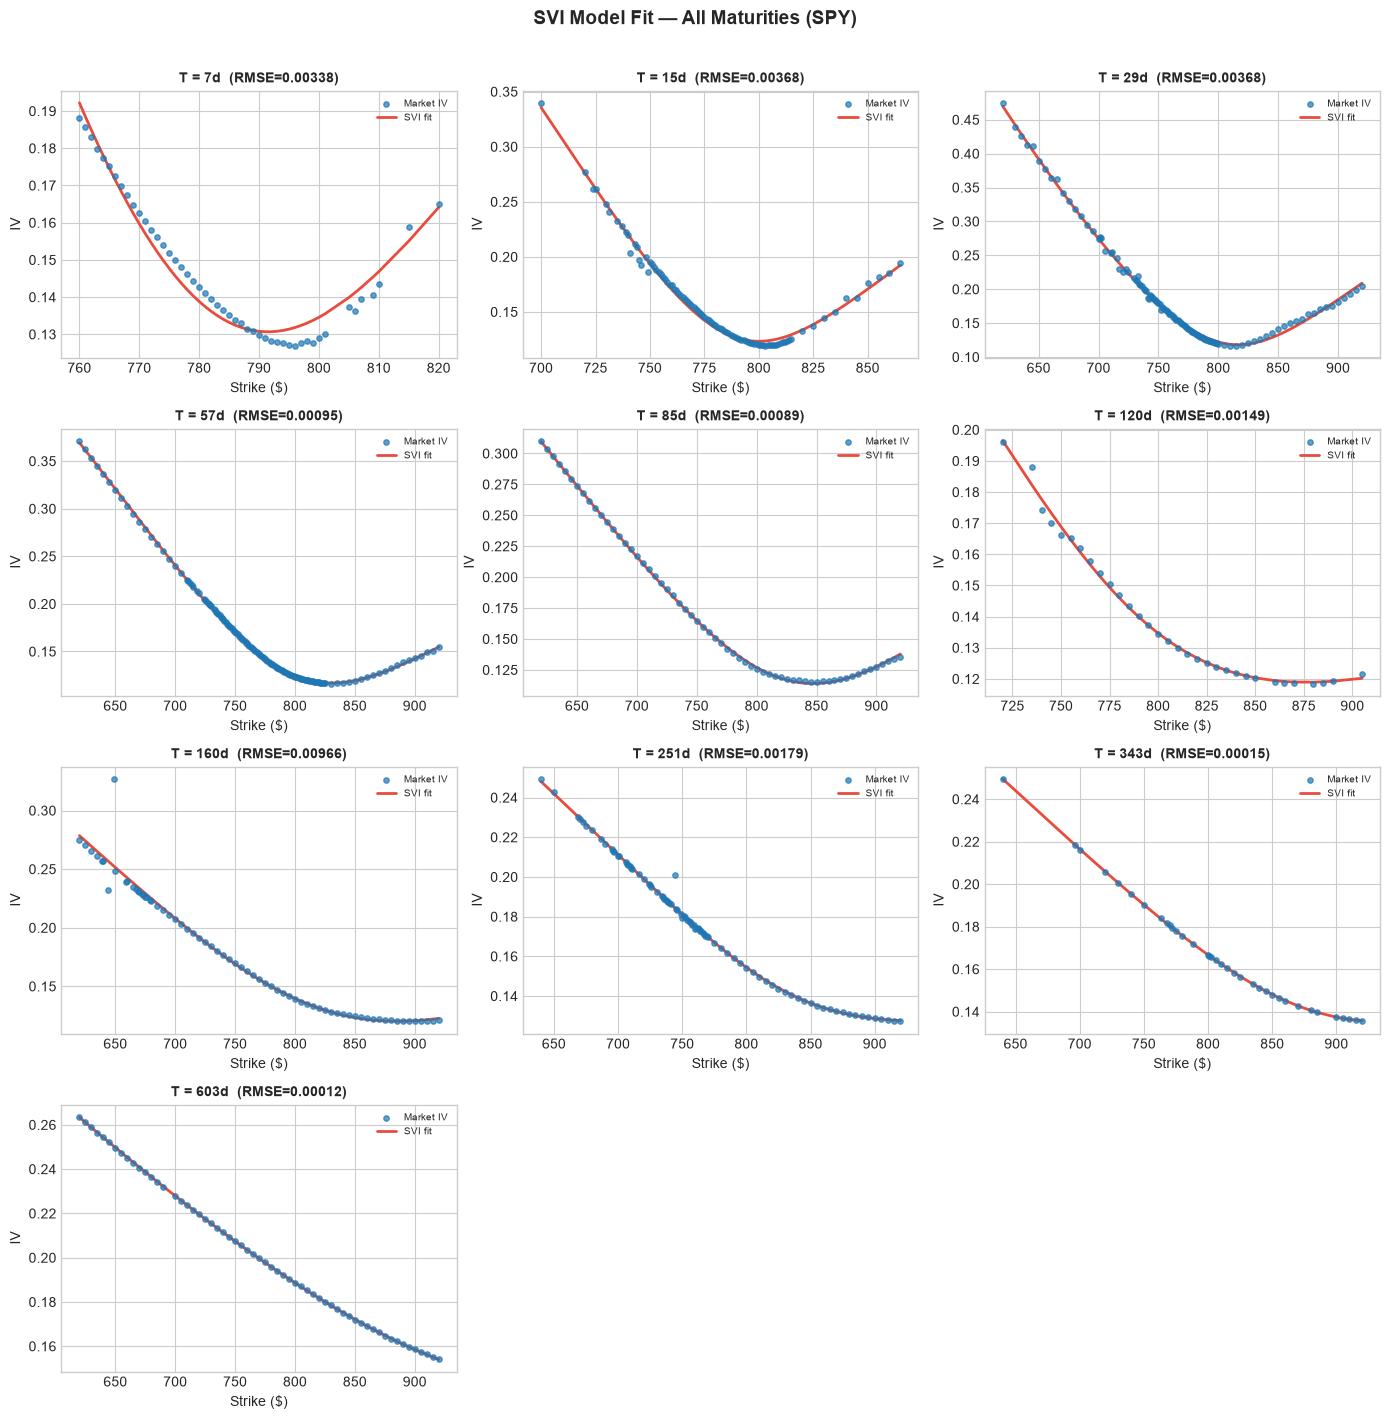

In [13]:
n_mats = len(svi_results)
if n_mats == 0:
    print("No SVI fits available to plot.")
else:
    ncols = min(3, n_mats)
    nrows = (n_mats + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows), squeeze=False)
    axes_flat = axes.ravel()

    for ax, (T_label, res) in zip(axes_flat, svi_results.items()):
        ax.scatter(res["strikes"], res["iv_market"], s=15, alpha=0.7,
                   color="#1f77b4", label="Market IV", zorder=3)
        ax.plot(res["strikes"], res["iv_fit"], lw=2, color="#e74c3c",
                label="SVI fit")
        ax.set_title(f"T = {T_label}  (RMSE={res['rmse']:.5f})",
                     fontsize=10, fontweight="bold")
        ax.legend(fontsize=7)
        ax.set_ylabel("IV")
        ax.set_xlabel("Strike ($)")

    for ax in axes_flat[n_mats:]:
        ax.set_visible(False)

    data_label = "SPY" if USE_REAL_DATA else "Synthetic"
    fig.suptitle(f"SVI Model Fit — All Maturities ({data_label})", fontsize=14, fontweight="bold", y=1.01)
    fig.tight_layout()
    plt.show()

In [14]:
svi_rmse_df = pd.DataFrame([
    {"Maturity": lab, "T (years)": res["T"], "SVI RMSE": res["rmse"]}
    for lab, res in svi_results.items()
])
display(svi_rmse_df.set_index("Maturity"))

,T (years),SVI RMSE
Maturity,,
7d,0.019165,0.003384
15d,0.041068,0.003685
29d,0.079398,0.003682
57d,0.156057,0.000952
85d,0.232717,0.000890
120d,0.328542,0.001488
160d,0.438056,0.009661
251d,0.687201,0.001791
343d,0.939083,0.000154


In [15]:
print("=== Calendar Arbitrage Check ===")
print("Total variance w(k) must be non-decreasing in T for each strike.\n")

sorted_labels = sorted(svi_results.keys(), key=lambda x: svi_results[x]["T"])
cal_violations = 0
for i in range(len(sorted_labels) - 1):
    lab1, lab2 = sorted_labels[i], sorted_labels[i + 1]
    r1, r2 = svi_results[lab1], svi_results[lab2]
    T1, T2 = r1["T"], r2["T"]
    common_K = np.intersect1d(r1["strikes"], r2["strikes"])
    for K_val in common_K:
        idx1 = np.where(r1["strikes"] == K_val)[0]
        idx2 = np.where(r2["strikes"] == K_val)[0]
        if len(idx1) == 0 or len(idx2) == 0:
            continue
        w1 = r1["iv_fit"][idx1[0]]**2 * T1
        w2 = r2["iv_fit"][idx2[0]]**2 * T2
        if w2 < w1 - 1e-6:
            cal_violations += 1

print(f"Calendar arbitrage violations: {cal_violations}")

print("\n=== Butterfly Arbitrage Check ===")
print("Gatheral's density condition g(k) ≥ 0 must hold on every SVI slice (no negative butterfly spreads).\n")


def svi_density_g(k, a, b, rho, m, sigma_svi):
    '''Gatheral's g(k) for an SVI slice; g(k) < 0 implies a negative risk-neutral density.'''
    km   = k - m
    root = np.sqrt(km**2 + sigma_svi**2)
    w    = a + b * (rho * km + root)
    w1   = b * (rho + km / root)
    w2   = b * sigma_svi**2 / root**3
    return (1 - k * w1 / (2 * w))**2 - (w1**2 / 4) * (1 / w + 0.25) + w2 / 2


bfly_violations = 0
for lab, res in svi_results.items():
    F_T = S0 * np.exp((r - q) * res["T"])
    k_grid = np.linspace(np.log(res["strikes"].min() / F_T),
                         np.log(res["strikes"].max() / F_T), 400)
    w_grid = svi_total_variance(k_grid, *res["params"])
    g_grid = svi_density_g(k_grid, *res["params"])
    bad = (w_grid <= 0) | (g_grid < 0)
    if np.any(bad):
        n_viol = int(np.sum(bad))
        bfly_violations += n_viol
        print(f"  {lab}: {n_viol} of {len(k_grid)} grid points violate g(k) ≥ 0 "
              f"(min g = {g_grid.min():.4f})")

if bfly_violations == 0:
    print("  No butterfly arbitrage violations detected.")
else:
    print(f"\n  Total butterfly violations: {bfly_violations}")

=== Calendar Arbitrage Check ===
Total variance w(k) must be non-decreasing in T for each strike.

Calendar arbitrage violations: 0

=== Butterfly Arbitrage Check ===
Gatheral's density condition g(k) ≥ 0 must hold on every SVI slice (no negative butterfly spreads).

  No butterfly arbitrage violations detected.


### SVI Results

* SVI fits all 10 expirations closely: the average IV error (RMSE) is **0.26 vol points** (0.0026).
* The best fits are the longest expirations (343 and 603 days, about **0.01 vol points**), whose smiles are nearly straight lines.
* The worst fit is the **160-day** slice (0.97 vol points), caused by the two noisy quotes near $644–$649 rather than by the model. The 7-day slice (0.34 points) is the hardest genuine shape: the model cannot fully follow the sharp bend near $790–$800.
* Every slice has a negative ρ (−0.06 to −0.70), the SVI parameter that tilts the smile into a put skew.
* **No calendar or butterfly arbitrage** was found: total variance rises with maturity at every shared strike, and Gatheral's $g(k)$ stays non-negative on all 10 slices.

---
## 6. SABR Model Fitting

The **SABR** (Stochastic Alpha Beta Rho) model describes the forward-price dynamics:

$$
dF = \alpha\,F^{\beta}\,dW_1, \qquad d\alpha = \nu\,\alpha\,dW_2, \qquad \langle dW_1, dW_2 \rangle = \rho\,dt
$$

**Parameters**: $\alpha$ (initial vol), $\beta$ (CEV exponent, controls backbone), $\rho$ (vol-spot correlation, drives skew), $\nu$ (vol-of-vol, drives smile curvature).

The **Hagan et al. (2002)** approximation gives the implied vol in closed form. Here $\beta$ is fixed at $0.5$, and $(\alpha, \rho, \nu)$ are calibrated per maturity slice.


In [16]:
def sabr_implied_vol(F, K, T, alpha, beta, rho, nu):
    '''Hagan SABR implied vol approximation (scalar-safe).'''
    eps = 1e-12
    if abs(F - K) < eps:
        FK_mid  = F
        vol_atm = (alpha / FK_mid**(1 - beta)) * (
            1 + ((1 - beta)**2 * alpha**2 / (24 * FK_mid**(2 * (1 - beta)))
                 + rho * beta * nu * alpha / (4 * FK_mid**(1 - beta))
                 + (2 - 3 * rho**2) * nu**2 / 24) * T
        )
        return max(vol_atm, 1e-6) if np.isfinite(vol_atm) else np.nan

    FK  = F * K
    lnFK = np.log(F / K)
    FK_beta = FK**((1 - beta) / 2)

    A = 1 + ((1 - beta)**2 / 24) * lnFK**2 + ((1 - beta)**4 / 1920) * lnFK**4
    z = (nu / alpha) * FK_beta * lnFK
    disc = np.sqrt(1 - 2 * rho * z + z**2)
    x_arg = (disc + z - rho) / (1 - rho + eps)
    if x_arg <= 0:
        return np.nan
    x_z = np.log(x_arg)
    if abs(x_z) < eps:
        zx_ratio = 1.0
    else:
        zx_ratio = z / x_z

    B = 1 + ((1 - beta)**2 * alpha**2 / (24 * FK**(1 - beta))
             + rho * beta * nu * alpha / (4 * FK_beta)
             + (2 - 3 * rho**2) * nu**2 / 24) * T

    vol = (alpha / (FK_beta * A)) * zx_ratio * B
    if not np.isfinite(vol):
        return np.nan
    return max(vol, 1e-6)


def sabr_iv_vec(K_arr, F, T, alpha, beta, rho, nu):
    return np.array([sabr_implied_vol(F, k, T, alpha, beta, rho, nu) for k in K_arr])


F_test = S0 * np.exp((r - q) * 0.25)
alpha_test = 0.20 * F_test**(1 - 0.5)
iv_test = sabr_implied_vol(F_test, F_test, 0.25, alpha_test, 0.5, -0.3, 0.4)
print(f"SABR IV test (ATM, T=0.25, α = 0.20·F^(1-β) = {alpha_test:.4f}): {iv_test:.6f}")

SABR IV test (ATM, T=0.25, α = 0.20·F^(1-β) = 5.5729): 0.200448


In [17]:
beta_fixed = 0.5

def fit_sabr_slice(strikes_slice, iv_slice, T, S=S0, r_=r, q_=q, beta=beta_fixed):
    '''Calibrate SABR (alpha, rho, nu) for one maturity slice.

    alpha is optimised in normalised form alpha_n = alpha / F^(1-beta), so the same
    bounds work for any price level (synthetic $100 or SPY near $700).
    '''
    F = S * np.exp((r_ - q_) * T)
    alpha_scale = F**(1 - beta)

    def objective(params):
        alpha_n, rho, nu = params
        iv_model = sabr_iv_vec(strikes_slice, F, T, alpha_n * alpha_scale, beta, rho, nu)
        if not np.all(np.isfinite(iv_model)):
            return 1e6
        return np.sum((iv_model - iv_slice)**2)

    best_res = None
    for a0 in [0.10, 0.20, 0.35, 0.50]:
        for rho0 in [-0.7, -0.4, -0.1, 0.0]:
            x0 = [a0, rho0, 0.3]
            bounds = [(1e-4, 3.0), (-0.999, 0.999), (1e-4, 5.0)]
            try:
                res = minimize(objective, x0, method="L-BFGS-B", bounds=bounds)
                if best_res is None or res.fun < best_res.fun:
                    best_res = res
            except Exception:
                continue

    if best_res is None:
        return None, np.inf, np.full_like(iv_slice, np.nan)

    alpha_n, rho_fit, nu_fit = best_res.x
    params = np.array([alpha_n * alpha_scale, rho_fit, nu_fit])
    iv_fit = sabr_iv_vec(strikes_slice, F, T, params[0], beta, params[1], params[2])
    rmse   = np.sqrt(np.mean((iv_fit - iv_slice)**2))
    return params, rmse, iv_fit


sabr_results = {}
for T_label in svi_results:
    res_svi = svi_results[T_label]
    T_val = res_svi["T"]
    params, rmse, iv_fit = fit_sabr_slice(res_svi["strikes"], res_svi["iv_market"], T_val)
    if params is None:
        continue
    sabr_results[T_label] = {
        "T": T_val, "params": params, "rmse": rmse,
        "strikes": res_svi["strikes"],
        "iv_market": res_svi["iv_market"],
        "iv_fit": iv_fit,
    }
    print(f"  {T_label:>6s}  RMSE={rmse:.6f}  α={params[0]:.4f}  "
          f"ρ={params[1]:+.4f}  ν={params[2]:.4f}")

      7d  RMSE=0.003612  α=4.4676  ρ=-0.6613  ν=5.0000


     15d  RMSE=0.005795  α=4.1516  ρ=-0.6832  ν=4.6482


     29d  RMSE=0.009672  α=3.9224  ρ=-0.7106  ν=3.9196


     57d  RMSE=0.005714  α=3.9422  ρ=-0.6908  ν=2.6336


     85d  RMSE=0.003070  α=3.9144  ρ=-0.6809  ν=1.9665


    120d  RMSE=0.002014  α=4.0914  ρ=-0.6578  ν=1.4545


    160d  RMSE=0.009983  α=4.1136  ρ=-0.6525  ν=1.4175


    251d  RMSE=0.001825  α=4.4095  ρ=-0.6294  ν=1.1056


    343d  RMSE=0.000198  α=4.6545  ρ=-0.6222  ν=0.9614


    603d  RMSE=0.000108  α=5.1647  ρ=-0.6467  ν=0.7086


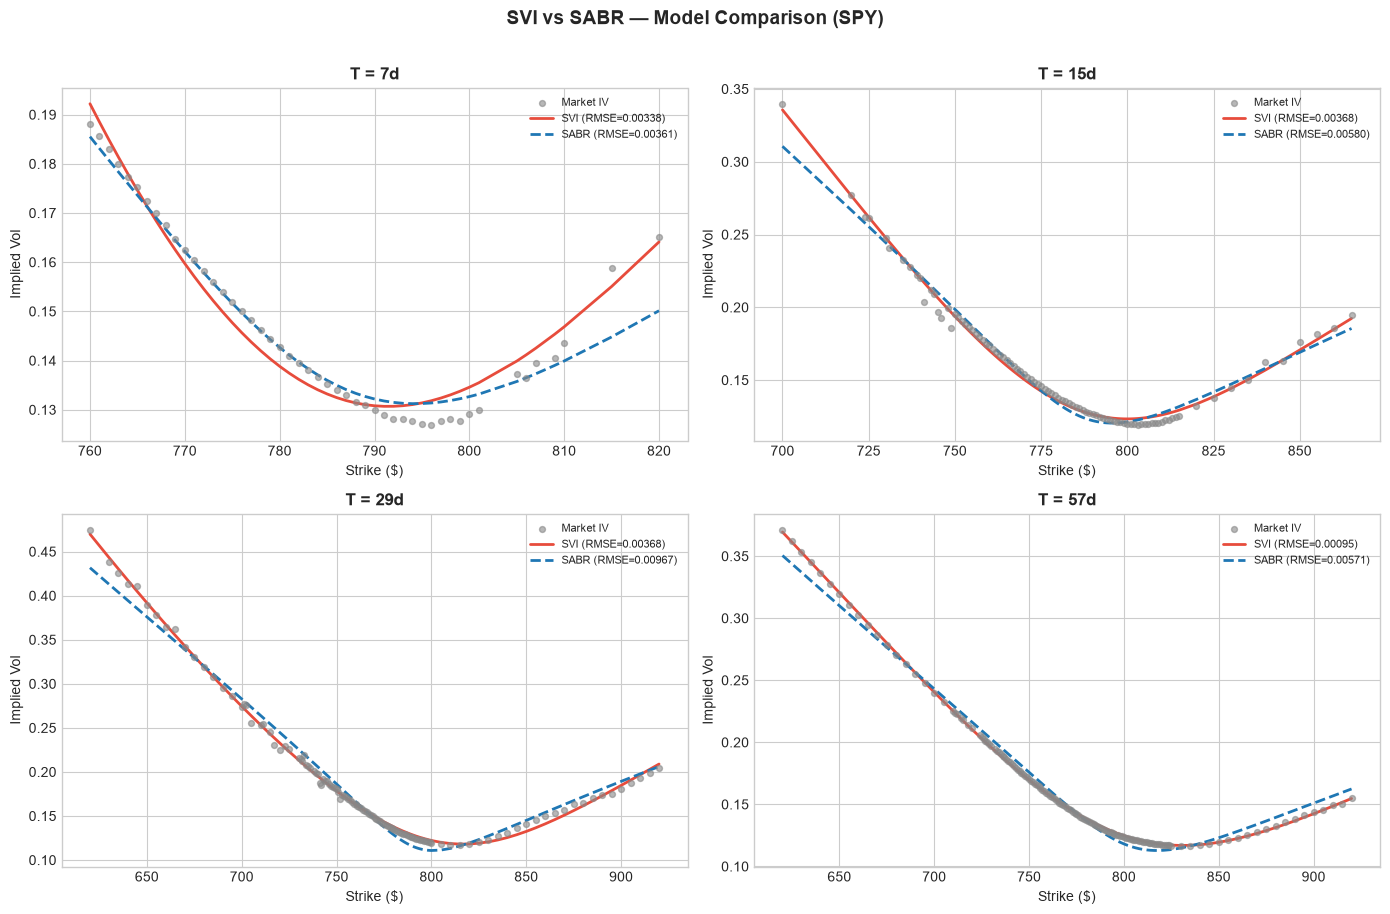

In [18]:
common_labels = [l for l in svi_results if l in sabr_results]
sel_mats = common_labels[:4]

if len(sel_mats) == 0:
    print("No maturities with both SVI and SABR fits to compare.")
else:
    ncols = min(2, len(sel_mats))
    nrows = (len(sel_mats) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4.5 * nrows), squeeze=False)
    axes_flat = axes.ravel()

    for ax, T_label in zip(axes_flat, sel_mats):
        res_s = svi_results[T_label]
        res_b = sabr_results[T_label]

        ax.scatter(res_s["strikes"], res_s["iv_market"], s=18, alpha=0.6,
                   color="#888888", label="Market IV", zorder=3)
        ax.plot(res_s["strikes"], res_s["iv_fit"], lw=2, color="#e74c3c",
                label=f"SVI (RMSE={res_s['rmse']:.5f})")
        ax.plot(res_b["strikes"], res_b["iv_fit"], lw=2, ls="--", color="#1f77b4",
                label=f"SABR (RMSE={res_b['rmse']:.5f})")
        ax.set_title(f"T = {T_label}", fontsize=12, fontweight="bold")
        ax.set_xlabel("Strike ($)")
        ax.set_ylabel("Implied Vol")
        ax.legend(fontsize=8)

    for ax in axes_flat[len(sel_mats):]:
        ax.set_visible(False)

    data_label = "SPY" if USE_REAL_DATA else "Synthetic"
    fig.suptitle(f"SVI vs SABR — Model Comparison ({data_label})", fontsize=14, fontweight="bold", y=1.01)
    fig.tight_layout()
    plt.show()

In [19]:
comparison = []
for lab in svi_results:
    row = {"Maturity": lab, "T": svi_results[lab]["T"],
           "SVI RMSE": svi_results[lab]["rmse"]}
    if lab in sabr_results:
        row["SABR RMSE"] = sabr_results[lab]["rmse"]
        row["Winner"] = "SVI" if row["SVI RMSE"] < row["SABR RMSE"] else "SABR"
    else:
        row["SABR RMSE"] = np.nan
        row["Winner"] = "SVI (only)"
    comparison.append(row)

comp_df = pd.DataFrame(comparison).set_index("Maturity")
display(comp_df)
print(f"\nAverage SVI  RMSE: {comp_df['SVI RMSE'].mean():.6f}")
sabr_valid = comp_df['SABR RMSE'].dropna()
if len(sabr_valid) > 0:
    print(f"Average SABR RMSE: {sabr_valid.mean():.6f}")

,T,SVI RMSE,SABR RMSE,Winner
Maturity,,,,
7d,0.019165,0.003384,0.003612,SVI
15d,0.041068,0.003685,0.005795,SVI
29d,0.079398,0.003682,0.009672,SVI
57d,0.156057,0.000952,0.005714,SVI
85d,0.232717,0.000890,0.003070,SVI
120d,0.328542,0.001488,0.002014,SVI
160d,0.438056,0.009661,0.009983,SVI
251d,0.687201,0.001791,0.001825,SVI
343d,0.939083,0.000154,0.000198,SVI



Average SVI  RMSE: 0.002581
Average SABR RMSE: 0.004199


### SVI vs SABR Results

* **SVI wins 9 of the 10 expirations.** Average RMSE is 0.0026 for SVI against 0.0042 for SABR; SABR only edges ahead at 603 days (0.000108 vs 0.000121), where both fits are almost perfect.
* SABR's largest misses are at **29 and 57 days** (0.97 and 0.57 vol points). The comparison chart shows why: with β fixed at 0.5, SABR undershoots the deep put wing (about 43% against a market 47.5% at $620 for 29 days) and dips too low near the bottom of the smile.
* SABR's vol-of-vol ν falls steadily with maturity, from **5.0 at 7 days** (its upper bound) to **0.71 at 603 days**, mirroring the smile curvature that fades with maturity. Hitting the bound at 7 days shows that fixed-β SABR struggles to bend the very short smile.
* SABR's correlation ρ is very stable at about **−0.62 to −0.71** across all expirations, a clean summary of the SPY spot-vol relationship (prices down, volatility up).

---
## 7. Greeks Surfaces & Risk Analysis

**Delta**, **Gamma**, and **Vega** are computed across the entire strike × maturity grid using the extracted implied volatilities and visualized as 3-D surfaces. These are the risk metrics a market maker or portfolio manager uses for scenario analysis.


In [20]:
calls_valid = calls.dropna(subset=["implied_vol"]).copy()
calls_valid = calls_valid[(calls_valid["implied_vol"] > 0.01) &
                          (calls_valid["implied_vol"] < 2.0)]

for greek_name in ["delta", "gamma", "vega"]:
    calls_valid[greek_name] = calls_valid.apply(
        lambda row: bs_greeks(S0, row["strike"], row["maturity"],
                              r, q, row["implied_vol"], "call")[greek_name],
        axis=1
    )

print(f"Greeks computed for {len(calls_valid):,} option records.")
display(calls_valid[["strike", "maturity", "implied_vol", "delta", "gamma", "vega"]].describe().round(4))

Greeks computed for 753 option records.


,strike,maturity,implied_vol,delta,gamma,vega
count,753.000000,753.000000,753.000000,753.000000,753.000000,753.000000
mean,774.301500,0.378700,0.173900,0.479900,0.005600,116.053900
std,67.404500,0.451500,0.054500,0.303600,0.004900,97.936300
min,620.000000,0.019200,0.115400,0.001200,0.000100,0.867200
25%,735.000000,0.079400,0.131700,0.185800,0.002100,42.460300
50%,774.000000,0.156100,0.161900,0.534000,0.003800,85.445800
75%,813.000000,0.438100,0.197300,0.749200,0.007900,172.529600
max,920.000000,1.650900,0.474900,0.954400,0.023600,385.840000


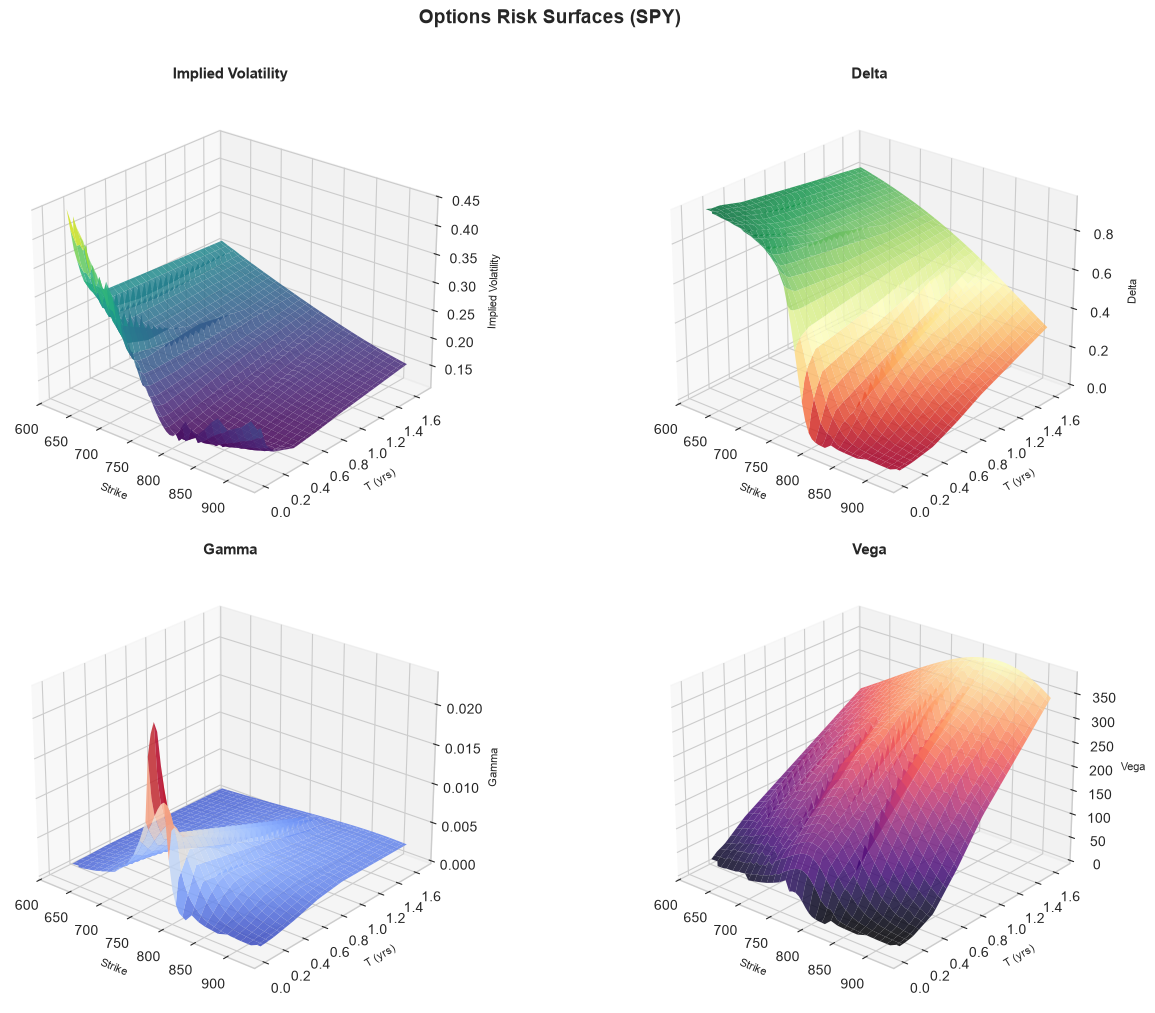

In [21]:
fields = ["implied_vol", "delta", "gamma", "vega"]
titles = ["Implied Volatility", "Delta", "Gamma", "Vega"]
cmaps  = [cm.viridis, cm.RdYlGn, cm.coolwarm, cm.magma]

fig, axes = plt.subplots(2, 2, figsize=(14, 10),
                         subplot_kw={"projection": "3d"})

for ax, field, title, cmap_val in zip(axes.flat, fields, titles, cmaps):
    X = calls_valid["strike"].values
    Y = calls_valid["maturity"].values
    Z = calls_valid[field].values

    xi = np.linspace(X.min(), X.max(), 60)
    yi = np.linspace(Y.min(), Y.max(), 60)
    XI, YI = np.meshgrid(xi, yi)
    try:
        ZI = griddata((X, Y), Z, (XI, YI), method="linear")
        ax.plot_surface(XI, YI, ZI, cmap=cmap_val, alpha=0.85,
                        edgecolor="none", antialiased=True)
    except Exception:
        ax.scatter(X, Y, Z, c=Z, cmap=cmap_val, s=5, alpha=0.5)
    ax.set_xlabel("Strike", fontsize=8)
    ax.set_ylabel("T (yrs)", fontsize=8)
    ax.set_zlabel(title, fontsize=8)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.view_init(elev=25, azim=-50)

data_label = "SPY" if USE_REAL_DATA else "Synthetic"
fig.suptitle(f"Options Risk Surfaces ({data_label})", fontsize=14, fontweight="bold", y=1.01)
fig.tight_layout()
plt.show()

### Greeks Results

* **Delta** runs from about 0.95 for deep in-the-money calls to near 0 for far out-of-the-money calls. The transition is sharpest at short maturities and spreads out as maturity grows.
* **Gamma** is concentrated in a narrow spike near the spot price at the shortest expirations (peaking at about 0.024 per $1 move), so short-dated near-the-money options carry the most re-hedging risk.
* **Vega** shows the opposite pattern: it is small at short maturities and climbs to about **386 per 1.00 of vol (≈$3.86 per vol point)** for long-dated near-the-money options, so the long end of the surface carries most of the volatility exposure.

---
## 8. Delta Hedging Simulation

### Replicating-Portfolio Theory

A **delta-neutral** portfolio holds:

$$
\Pi = -V + \Delta \cdot S
$$

where $V$ is the option value and $\Delta = \partial V / \partial S$. Rebalancing $\Delta$ at each time step replicates the option payoff up to **discrete-hedging error** and **gamma P&L**:

$$
\text{P\&L}_{\text{hedge}} \approx \tfrac{1}{2}\,\Gamma\,(\Delta S)^2\,dt
$$

Simulation steps:
1. Sell one ATM call.
2. Delta-hedge at various frequencies (cash earns $r$, the stock position earns the dividend yield $q$).
3. Measure final P&L distribution over many Monte-Carlo paths.

**Real data mode**: Uses GBM calibrated to SPY's actual realized volatility from the historical data.


In [22]:
hedge_sigma = 0.25

if USE_REAL_DATA:
    try:
        import yfinance as yf
        spy_hist = yf.Ticker("SPY").history(period="1y")
        log_returns = np.log(spy_hist['Close'] / spy_hist['Close'].shift(1)).dropna()
        hedge_sigma = float(log_returns.std() * np.sqrt(252))
        print(f"SPY realized vol (1-year): {hedge_sigma:.4f}")
    except Exception:
        print(f"Using default hedge vol: {hedge_sigma:.4f}")
else:
    print(f"Using synthetic hedge vol: {hedge_sigma:.4f}")

T_hedge  = 0.25
K_hedge  = S0
n_days   = int(T_hedge * 252)
dt       = T_hedge / n_days

print(f"\nHedge parameters:")
print(f"  T = {T_hedge} years ({n_days} trading days)")
print(f"  K = ${K_hedge:.2f} (ATM)")
print(f"  σ = {hedge_sigma:.4f}")

SPY realized vol (1-year): 0.1271

Hedge parameters:
  T = 0.25 years (63 trading days)
  K = $769.05 (ATM)
  σ = 0.1271


In [23]:
np.random.seed(42)
Z      = np.random.standard_normal(n_days)
S_path = np.zeros(n_days + 1)
S_path[0] = S0
for i in range(n_days):
    S_path[i+1] = S_path[i] * np.exp((r - q - 0.5*hedge_sigma**2)*dt
                                      + hedge_sigma*np.sqrt(dt)*Z[i])

option_price_init = bs_price(S0, K_hedge, T_hedge, r, q, hedge_sigma, "call")
cash       = option_price_init
stock_held = 0.0
pnl_daily  = np.zeros(n_days + 1)
delta_path = np.zeros(n_days + 1)

for i in range(n_days):
    T_rem = max(T_hedge - i * dt, 1e-8)
    delta_new = bs_greeks(S_path[i], K_hedge, T_rem, r, q,
                          hedge_sigma, "call")["delta"]
    delta_path[i] = delta_new
    cash -= (delta_new - stock_held) * S_path[i]
    stock_held = delta_new
    cash = cash * np.exp(r * dt) + stock_held * S_path[i] * (np.exp(q * dt) - 1.0)

    T_next = T_hedge - (i + 1) * dt
    if T_next > 1e-8:
        option_value = bs_price(S_path[i+1], K_hedge, T_next, r, q, hedge_sigma, "call")
    else:
        option_value = max(S_path[i+1] - K_hedge, 0.0)
    pnl_daily[i+1] = cash + stock_held * S_path[i+1] - option_value

payoff = max(S_path[-1] - K_hedge, 0.0)
final_pnl = cash + stock_held * S_path[-1] - payoff
delta_path[-1] = 1.0 if S_path[-1] > K_hedge else 0.0

print(f"Initial premium received:  ${option_price_init:.4f}")
print(f"Final stock price:         ${S_path[-1]:.4f}")
print(f"Option payoff:             ${payoff:.4f}")
print(f"Hedge P&L:                 ${final_pnl:.4f}")

Initial premium received:  $23.1941
Final stock price:         $709.2540
Option payoff:             $0.0000
Hedge P&L:                 $0.5370


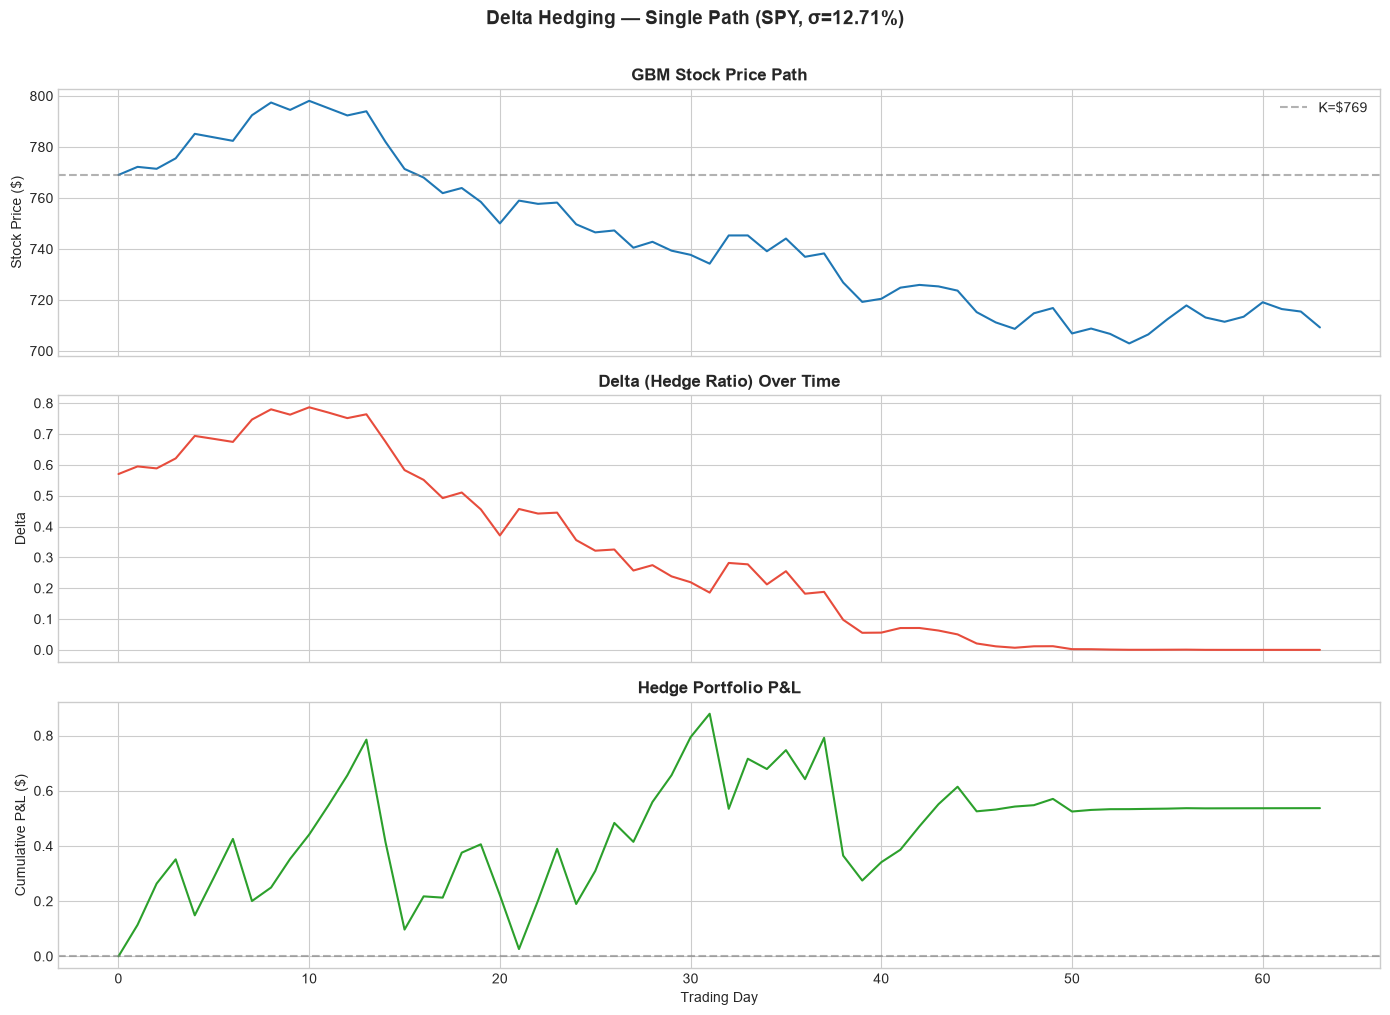

In [24]:
days_arr = np.arange(n_days + 1)

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(days_arr, S_path, lw=1.5, color="#1f77b4")
axes[0].axhline(K_hedge, ls="--", color="grey", alpha=0.6, label=f"K=${K_hedge:.0f}")
axes[0].set_ylabel("Stock Price ($)")
axes[0].set_title("GBM Stock Price Path", fontweight="bold")
axes[0].legend()

axes[1].plot(days_arr, delta_path, lw=1.5, color="#e74c3c")
axes[1].set_ylabel("Delta")
axes[1].set_title("Delta (Hedge Ratio) Over Time", fontweight="bold")

axes[2].plot(days_arr, pnl_daily, lw=1.5, color="#2ca02c")
axes[2].axhline(0, ls="--", color="grey", alpha=0.6)
axes[2].set_ylabel("Cumulative P&L ($)")
axes[2].set_xlabel("Trading Day")
axes[2].set_title("Hedge Portfolio P&L", fontweight="bold")

data_label = "SPY" if USE_REAL_DATA else "Synthetic"
fig.suptitle(f"Delta Hedging — Single Path ({data_label}, σ={hedge_sigma:.2%})",
             fontsize=14, fontweight="bold", y=1.01)
fig.tight_layout()
plt.show()

In [25]:
n_mc = 1000


def simulate_hedge_pnl(n_paths, rebalance_every=1, seed=42):
    '''Final P&L of a short ATM call delta-hedged every `rebalance_every` days, across GBM paths.'''
    rng = np.random.default_rng(seed)
    Z_mc = rng.standard_normal((n_paths, n_days))
    log_steps = (r - q - 0.5 * hedge_sigma**2) * dt + hedge_sigma * np.sqrt(dt) * Z_mc
    S_mc = S0 * np.exp(np.hstack([np.zeros((n_paths, 1)), np.cumsum(log_steps, axis=1)]))

    cash_mc  = np.full(n_paths, option_price_init)
    stock_mc = np.zeros(n_paths)
    for i in range(n_days):
        if i % rebalance_every == 0:
            T_rem = max(T_hedge - i * dt, 1e-8)
            delta_mc = bs_greeks(S_mc[:, i], K_hedge, T_rem, r, q,
                                 hedge_sigma, "call")["delta"]
            cash_mc -= (delta_mc - stock_mc) * S_mc[:, i]
            stock_mc = delta_mc
        cash_mc = cash_mc * np.exp(r * dt) + stock_mc * S_mc[:, i] * (np.exp(q * dt) - 1.0)

    payoff_mc = np.maximum(S_mc[:, -1] - K_hedge, 0.0)
    return cash_mc + stock_mc * S_mc[:, -1] - payoff_mc


final_pnls = simulate_hedge_pnl(n_mc)

print(f"MC Delta-Hedging P&L (n={n_mc})")
print(f"  Mean:   ${final_pnls.mean():.4f}")
print(f"  Std:    ${final_pnls.std():.4f}")
print(f"  Min:    ${final_pnls.min():.4f}")
print(f"  Max:    ${final_pnls.max():.4f}")

MC Delta-Hedging P&L (n=1000)
  Mean:   $-0.0320
  Std:    $2.0395
  Min:    $-13.9437
  Max:    $6.7038


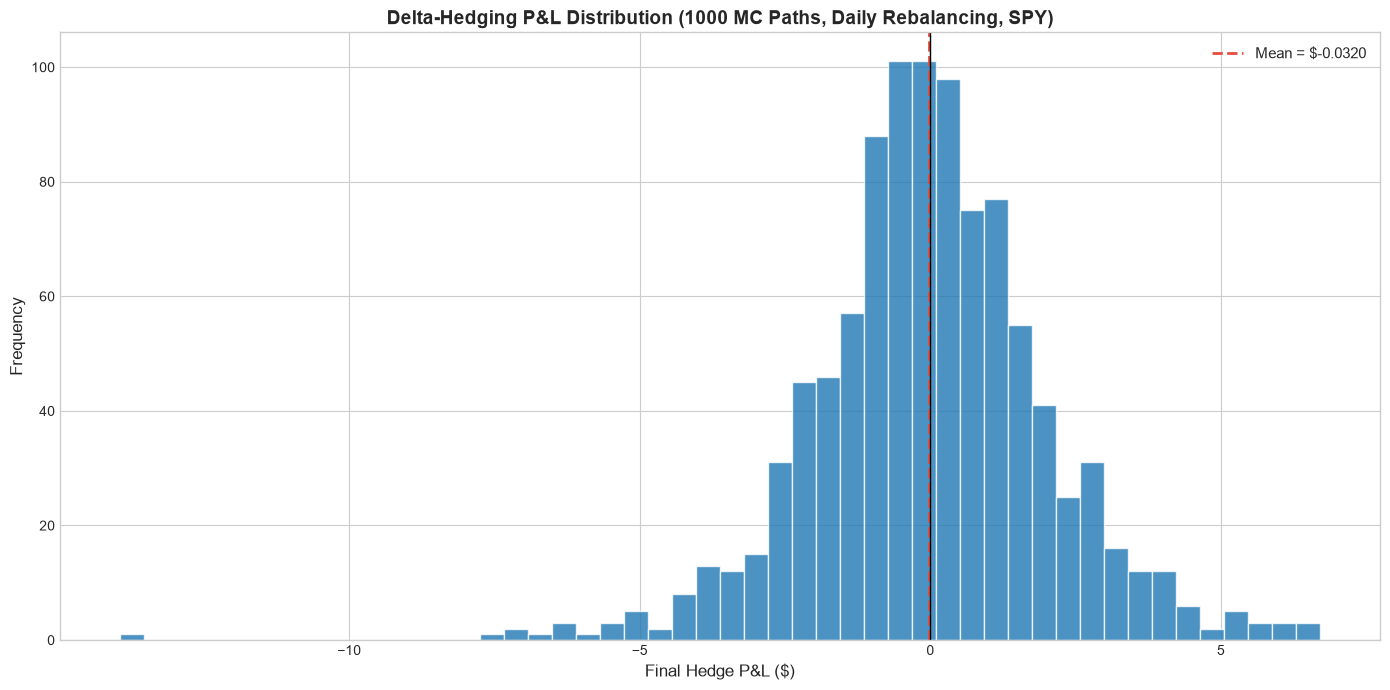

In [26]:
fig, ax = plt.subplots(figsize=(14, 7))
ax.hist(final_pnls, bins=50, edgecolor="white", color="#1f77b4", alpha=0.8)
ax.axvline(final_pnls.mean(), color="#e74c3c", lw=2, ls="--",
           label=f"Mean = ${final_pnls.mean():.4f}")
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Final Hedge P&L ($)", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)
data_label = "SPY" if USE_REAL_DATA else "Synthetic"
ax.set_title(f"Delta-Hedging P&L Distribution ({n_mc} MC Paths, Daily Rebalancing, {data_label})",
             fontsize=14, fontweight="bold")
ax.legend(fontsize=11)
fig.tight_layout()
plt.show()

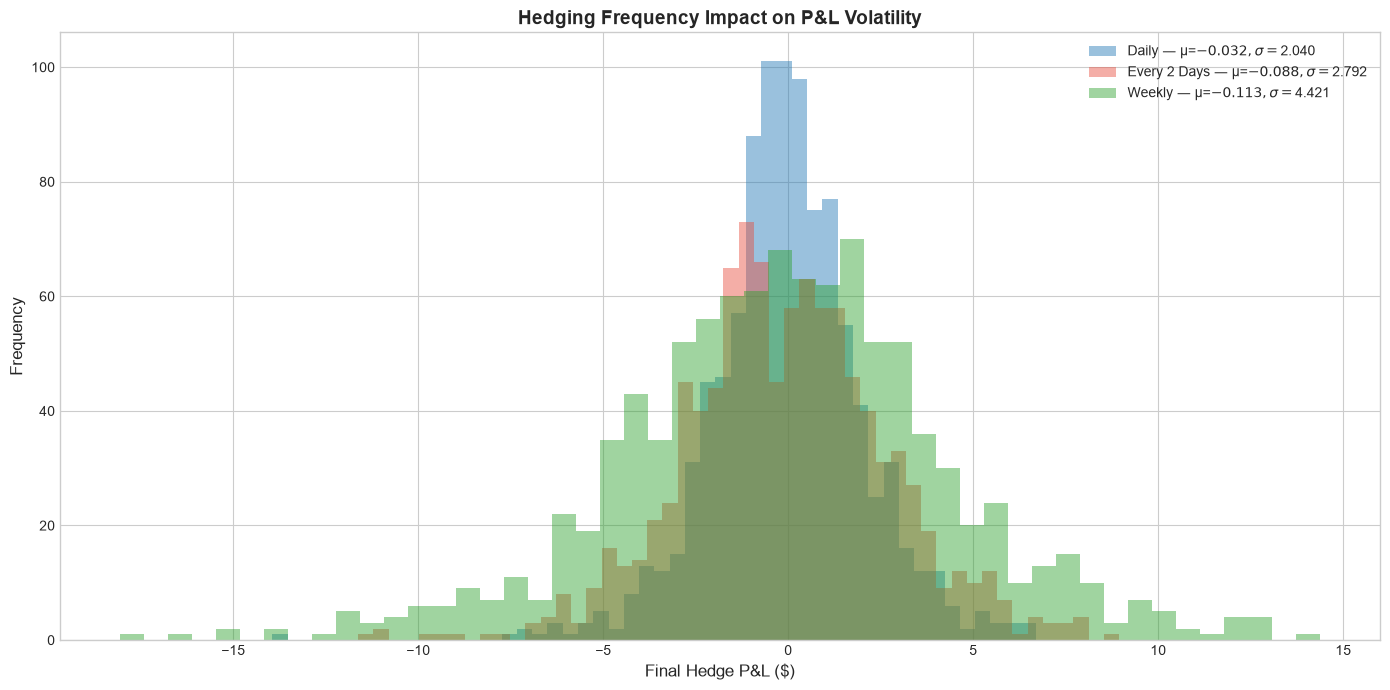


Summary:
            Daily  Mean=$-0.0320   Std=$2.0395
     Every 2 Days  Mean=$-0.0876   Std=$2.7923
           Weekly  Mean=$-0.1129   Std=$4.4209


In [27]:
frequencies = {"Daily": 1, "Every 2 Days": 2, "Weekly": 5}
freq_results = {label: simulate_hedge_pnl(n_mc, rebalance_every=step)
                for label, step in frequencies.items()}

fig, ax = plt.subplots(figsize=(14, 7))
colors_f = ["#1f77b4", "#e74c3c", "#2ca02c"]
for (label, pnls), col in zip(freq_results.items(), colors_f):
    ax.hist(pnls, bins=50, alpha=0.45, color=col,
            label=f"{label} — μ=${pnls.mean():.3f}, σ=${pnls.std():.3f}")

ax.set_xlabel("Final Hedge P&L ($)", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)
ax.set_title("Hedging Frequency Impact on P&L Volatility",
             fontsize=14, fontweight="bold")
ax.legend(fontsize=10)
fig.tight_layout()
plt.show()

print("\nSummary:")
for label, pnls in freq_results.items():
    print(f"  {label:>15s}  Mean=${pnls.mean():+.4f}   Std=${pnls.std():.4f}")

### Delta-Hedging Results

* **Setup**: short one 3-month ATM call (K = $769.05) priced at the SPY 1-year realized vol of **12.71%**, for a premium of **$23.19**.
* **Single path**: SPY drifts down to about $709, the call expires worthless, and delta decays from 0.57 to 0. The hedge finishes at **+$0.54**, with mark-to-market P&L moving between $0 and about $0.88 along the way.
* **1,000 paths, daily rebalancing**: mean P&L is **−$0.03** (statistically zero) with a standard deviation of **$2.04**, about 9% of the premium. The distribution has a longer left tail (worst −$13.94 vs best +$6.70), the cost of being short gamma when the price makes a large move near the strike.
* **Rebalancing frequency**: the P&L standard deviation rises from $2.04 (daily) to $2.79 (every 2 days) and $4.42 (weekly). Those are 1.37× and 2.17× the daily figure, close to √2 = 1.41 and √5 = 2.24, so hedging error grows with the **square root** of the time between rebalances rather than in proportion to it. Mean P&L stays near zero at every frequency (−$0.03 to −$0.11).

---
## 9. Volatility Term Structure Analysis

The ATM implied volatility term structure reveals the market's expectations of future variance. Key regimes:

* **Backwardation** (inverted): short-dated vol > long-dated vol — market expects elevated near-term uncertainty to normalise.
* **Contango** (normal): short-dated vol < long-dated vol — market is calm now but prices in future risk.

With real SPY data, the term structure shape reflects actual market conditions — whether the market is in a low-vol regime, pre-event pricing, or post-selloff recovery.


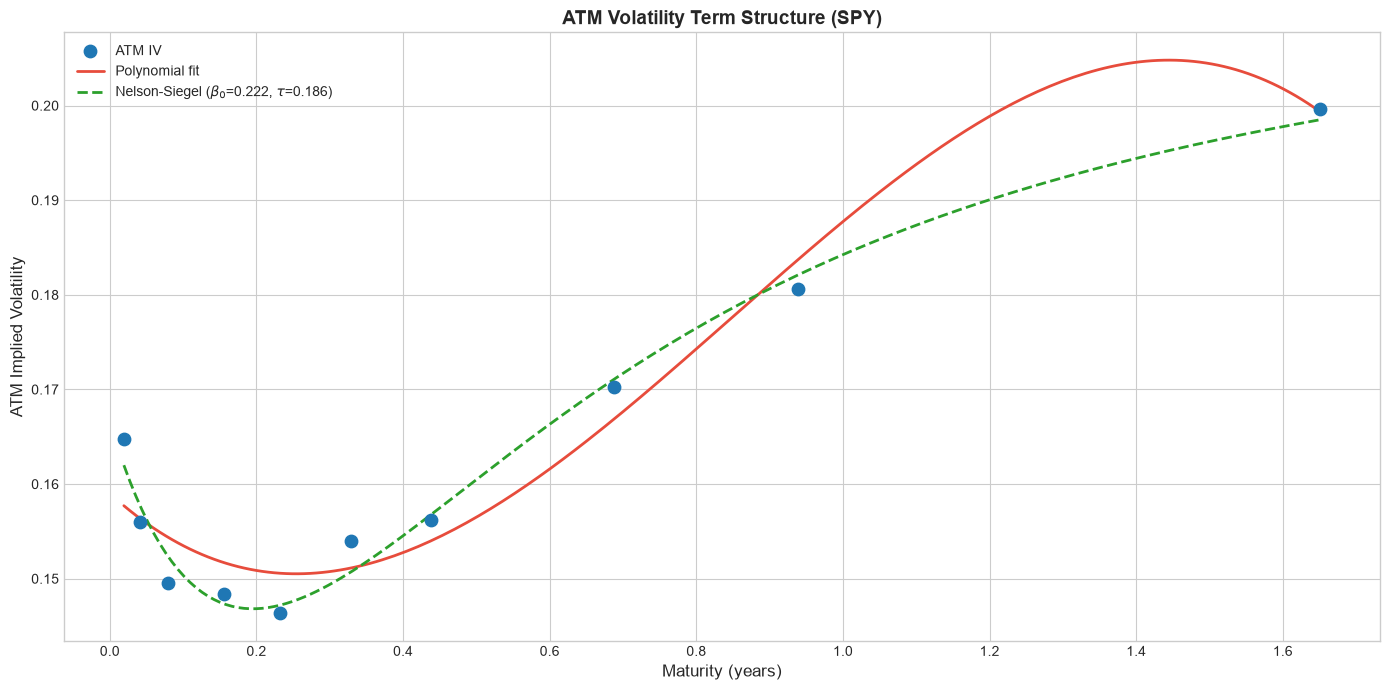

ATM term structure (nearest-to-money strikes):
      7d (K=$769):  IV = 0.1648
     15d (K=$769):  IV = 0.1560
     29d (K=$769):  IV = 0.1496
     57d (K=$769):  IV = 0.1484
     85d (K=$770):  IV = 0.1463
    120d (K=$770):  IV = 0.1540
    160d (K=$770):  IV = 0.1562
    251d (K=$769):  IV = 0.1702
    343d (K=$770):  IV = 0.1806
    603d (K=$770):  IV = 0.1996

Polynomial fit RMSE:    0.00370
Nelson-Siegel fit RMSE: 0.00189


In [28]:
atm_data = []
for T_val in sorted(calls_valid["maturity"].unique()):
    sub = calls_valid[calls_valid["maturity"] == T_val].copy()
    if len(sub) == 0:
        continue
    sub['dist_from_atm'] = abs(sub['strike'] - S0)
    atm_row = sub.loc[sub['dist_from_atm'].idxmin()]
    atm_data.append({
        'maturity': T_val,
        'strike': atm_row['strike'],
        'implied_vol': atm_row['implied_vol'],
    })

atm_df = pd.DataFrame(atm_data).sort_values('maturity')
T_arr  = atm_df['maturity'].values
iv_arr = atm_df['implied_vol'].values

poly_coef = np.polyfit(T_arr, iv_arr, min(3, len(T_arr) - 1))
poly_fn   = np.poly1d(poly_coef)

def nelson_siegel(T, b0, b1, b2, tau):
    x = T / tau
    factor1 = (1 - np.exp(-x)) / np.maximum(x, 1e-8)
    factor2 = factor1 - np.exp(-x)
    return b0 + b1 * factor1 + b2 * factor2

ns_label = None
ns_popt = None
if len(T_arr) >= 4:
    try:
        ns_popt, _ = curve_fit(nelson_siegel, T_arr, iv_arr,
                               p0=[iv_arr.mean(), 0.05, 0.01, 0.5],
                               bounds=([0, -1, -1, 0.01], [1, 1, 1, 5.0]),
                               maxfev=5000)
        ns_label = f"Nelson-Siegel ($\\beta_0$={ns_popt[0]:.3f}, $\\tau$={ns_popt[3]:.3f})"
    except Exception:
        ns_label = None

T_smooth = np.linspace(T_arr.min(), T_arr.max(), 200)

fig, ax = plt.subplots(figsize=(14, 7))
ax.scatter(T_arr, iv_arr, s=80, zorder=5, color="#1f77b4", label="ATM IV")
ax.plot(T_smooth, poly_fn(T_smooth), lw=2, color="#e74c3c", label="Polynomial fit")
if ns_popt is not None:
    ax.plot(T_smooth, nelson_siegel(T_smooth, *ns_popt), lw=2, ls="--",
            color="#2ca02c", label=ns_label)

ax.set_xlabel("Maturity (years)", fontsize=12)
ax.set_ylabel("ATM Implied Volatility", fontsize=12)
data_label = "SPY" if USE_REAL_DATA else "Synthetic"
ax.set_title(f"ATM Volatility Term Structure ({data_label})", fontsize=14, fontweight="bold")
ax.legend(fontsize=10)
fig.tight_layout()
plt.show()

print(f"ATM term structure (nearest-to-money strikes):")
for _, row in atm_df.iterrows():
    T_label = t_to_label.get(row['maturity'], f"{row['maturity']:.3f}y")
    print(f"  {T_label:>6s} (K=${row['strike']:.0f}):  IV = {row['implied_vol']:.4f}")


poly_rmse = np.sqrt(np.mean((poly_fn(T_arr) - iv_arr)**2))
print(f"\nPolynomial fit RMSE:    {poly_rmse:.5f}")
if ns_popt is not None:
    ns_rmse = np.sqrt(np.mean((nelson_siegel(T_arr, *ns_popt) - iv_arr)**2))
    print(f"Nelson-Siegel fit RMSE: {ns_rmse:.5f}")

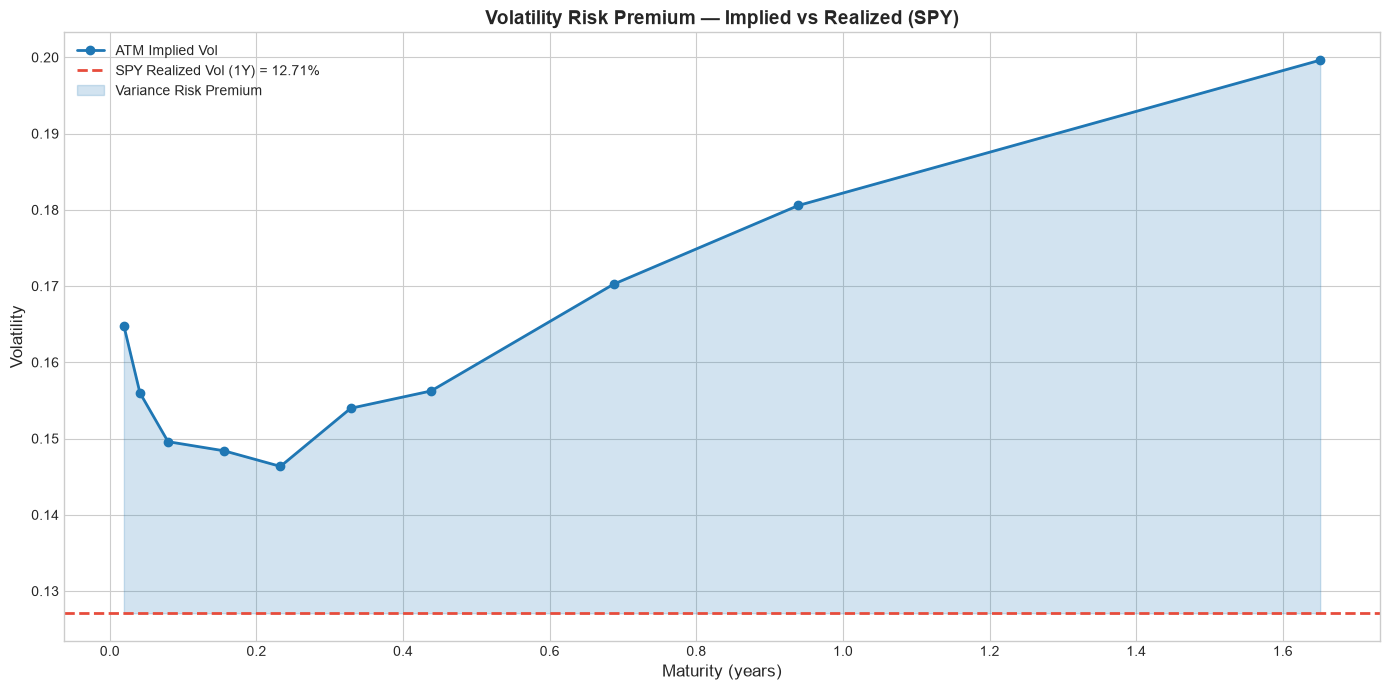

Volatility Risk Premium (implied − realized) by maturity:
      7d: VRP = +0.0377 (+3.77%)
     15d: VRP = +0.0289 (+2.89%)
     29d: VRP = +0.0225 (+2.25%)
     57d: VRP = +0.0213 (+2.13%)
     85d: VRP = +0.0193 (+1.93%)
    120d: VRP = +0.0269 (+2.69%)
    160d: VRP = +0.0292 (+2.92%)
    251d: VRP = +0.0432 (+4.32%)
    343d: VRP = +0.0535 (+5.35%)
    603d: VRP = +0.0725 (+7.25%)

Average VRP: +0.0355 (+3.55%)


In [29]:
if USE_REAL_DATA:
    try:
        import yfinance as yf
        spy_hist = yf.Ticker("SPY").history(period="1y")
        log_ret = np.log(spy_hist['Close'] / spy_hist['Close'].shift(1)).dropna()
        realized_vol = float(log_ret.std() * np.sqrt(252))
        rv_label = "SPY Realized Vol (1Y)"
    except Exception:
        realized_vol = 0.15
        rv_label = "Estimated Realized Vol"
else:
    realized_vol = 0.20
    rv_label = "True Generating Vol"

fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(T_arr, iv_arr, marker="o", lw=2, color="#1f77b4", label="ATM Implied Vol")
ax.axhline(realized_vol, ls="--", color="#e74c3c", lw=2,
           label=f"{rv_label} = {realized_vol:.2%}")
ax.fill_between(T_arr, realized_vol, iv_arr, alpha=0.2,
                where=(iv_arr > realized_vol), color="#1f77b4",
                label="Variance Risk Premium")

ax.set_xlabel("Maturity (years)", fontsize=12)
ax.set_ylabel("Volatility", fontsize=12)
data_label = "SPY" if USE_REAL_DATA else "Synthetic"
ax.set_title(f"Volatility Risk Premium — Implied vs Realized ({data_label})",
             fontsize=14, fontweight="bold")
ax.legend(fontsize=10)
fig.tight_layout()
plt.show()

vrp = iv_arr - realized_vol
print(f"Volatility Risk Premium (implied − realized) by maturity:")
for i, (t_val, iv_val) in enumerate(zip(T_arr, iv_arr)):
    T_label = t_to_label.get(t_val, f"{t_val:.3f}y")
    print(f"  {T_label:>6s}: VRP = {vrp[i]:+.4f} ({vrp[i]*100:+.2f}%)")
print(f"\nAverage VRP: {vrp.mean():+.4f} ({vrp.mean()*100:+.2f}%)")

### Term Structure & Volatility Risk Premium Results

* **ATM curve shape**: 16.5% (7d) → 15.6% (15d) → 15.0% (29d) → 14.8% (57d) → **14.6% low (85d)** → 15.4% (120d) → 15.6% (160d) → 17.0% (251d) → 18.1% (343d) → **20.0% (603d)**. A short inversion over the first three months gives way to a clearly upward-sloping curve.
* **Curve fits**: Nelson-Siegel tracks the points about twice as well as the cubic polynomial (RMSE 0.0019 vs 0.0037), with a long-run level $\beta_0$ of 22.2%. The polynomial also overshoots to about 20.5% near 1.45 years and then bends down, a fitting artifact rather than a market feature.
* **Volatility risk premium**: ATM implied vol sits above the SPY 1-year realized vol (12.71%) at **every** maturity, by between +1.93 points (85d) and +7.25 points (603d), an average of **+3.55 points**. The large long-dated gap compares a 1.6-year forward-looking vol with a trailing 1-year window, so it also reflects the upward-sloping term structure, not only a risk premium.

---
## 10. Mispricing Detection

Potential arbitrage or mispricing opportunities are flagged using two approaches:

1. **Model vs Market**: Compare SVI model IVs to market IVs — large deviations may signal mispricings or stale quotes.
2. **Put-Call Parity**: For European options: $C - P = S\,e^{-qT} - K\,e^{-rT}$. Violations indicate trading opportunities, early-exercise premium (SPY options are American), or data staleness.

> **Note**: SPY options are American-style (ETF options). Parity residuals can also come from the early-exercise premium and from the rate and dividend inputs, so a residual on its own is not proof of arbitrage.


In [30]:
threshold_vol  = 0.02
threshold_price = 1.00

mispricings = []
for T_label, res in svi_results.items():
    T_val = res["T"]
    for i, K_val in enumerate(res["strikes"]):
        iv_mkt   = res["iv_market"][i]
        iv_model = res["iv_fit"][i]
        price_mkt   = bs_price(S0, K_val, T_val, r, q, iv_mkt, "call")
        price_model = bs_price(S0, K_val, T_val, r, q, iv_model, "call")
        vol_diff   = iv_mkt - iv_model
        price_diff = price_mkt - price_model
        if abs(vol_diff) > threshold_vol or abs(price_diff) > threshold_price:
            mispricings.append({
                "Maturity": T_label, "Strike": K_val,
                "Market IV": iv_mkt, "SVI IV": iv_model,
                "IV Diff": vol_diff,
                "Mkt Price": price_mkt, "Model Price": price_model,
                "Price Diff": price_diff,
            })

misp_df = pd.DataFrame(mispricings)
if len(misp_df) > 0:
    print(f"Flagged {len(misp_df)} potential mispricings (|ΔIV| > {threshold_vol:.0%} "
          f"or |ΔPrice| > ${threshold_price}):\n")
    display(misp_df.round(4).head(20))
else:
    print("No significant mispricings detected — SVI fit is tight.")

Flagged 3 potential mispricings (|ΔIV| > 2% or |ΔPrice| > $1.0):



,Maturity,Strike,Market IV,SVI IV,IV Diff,Mkt Price,Model Price,Price Diff
0,160d,644.000000,0.232200,0.256800,-0.024600,140.195000,142.378800,-2.183800
1,160d,649.000000,0.327100,0.252300,0.074800,146.270000,137.778200,8.491800
2,251d,744.000000,0.200900,0.184600,0.016300,74.155000,70.445700,3.709300


In [31]:
thr = 1.0 if USE_REAL_DATA else 0.10
key_cols = ["strike", "maturity"]

call_px = (options_df[options_df["option_type"] == "call"]
           .groupby(key_cols, as_index=False)["market_price"].first()
           .rename(columns={"market_price": "C"}))
put_px  = (options_df[options_df["option_type"] == "put"]
           .groupby(key_cols, as_index=False)["market_price"].first()
           .rename(columns={"market_price": "P"}))

parity_df = call_px.merge(put_px, on=key_cols, how="inner")
parity_df["C-P"] = parity_df["C"] - parity_df["P"]
parity_df["Se^(-qT)-Ke^(-rT)"] = (S0 * np.exp(-q * parity_df["maturity"])
                                  - parity_df["strike"] * np.exp(-r * parity_df["maturity"]))
parity_df["Violation"] = parity_df["C-P"] - parity_df["Se^(-qT)-Ke^(-rT)"]

viol = parity_df[parity_df["Violation"].abs() > thr].sort_values(key_cols[::-1])
pv_df = pd.DataFrame({
    "Maturity": viol["maturity"].map(lambda t: t_to_label.get(t, f"{t:.3f}y")),
    "Strike": viol["strike"],
    "C-P": viol["C-P"],
    "Se^(-qT)-Ke^(-rT)": viol["Se^(-qT)-Ke^(-rT)"],
    "Violation": viol["Violation"],
}).reset_index(drop=True)

thr_str = f"${thr:.2f}"
if len(pv_df) > 0:
    print(f"Put-Call Parity violations (|error| > {thr_str}): {len(pv_df)} "
          f"of {len(parity_df)} call/put pairs\n")
    display(pv_df.round(4).head(15))
    if USE_REAL_DATA:
        print("\n📌 Note: residuals here mostly reflect the flat rate/dividend inputs and")
        print("   American exercise, not pure arbitrage opportunities.")
else:
    print(f"All {len(parity_df)} put-call parity relations hold within {thr_str} tolerance.")

parity_summary = (parity_df
                  .assign(Maturity=parity_df["maturity"].map(lambda t: t_to_label.get(t, f"{t:.3f}y")),
                          Breach=parity_df["Violation"].abs() > thr)
                  .groupby(["maturity", "Maturity"])
                  .agg(Pairs=("Violation", "size"),
                       Breaches=("Breach", "sum"),
                       Median_Violation=("Violation", "median"))
                  .reset_index(level=0, drop=True))
print("\nParity residual by maturity (C-P minus theoretical):")
display(parity_summary.round(4))

Put-Call Parity violations (|error| > $1.00): 224 of 505 call/put pairs



,Maturity,Strike,C-P,Se^(-qT)-Ke^(-rT),Violation
0,15d,700.000000,71.295000,70.109000,1.186000
1,15d,720.000000,51.350000,50.151000,1.199000
2,15d,724.000000,47.255000,46.159400,1.095600
3,15d,725.000000,46.330000,45.161500,1.168500
4,15d,730.000000,41.360000,40.172000,1.188000
5,15d,731.000000,40.210000,39.174100,1.035900
6,15d,735.000000,36.305000,35.182500,1.122500
7,15d,737.000000,34.335000,33.186600,1.148400
8,15d,739.000000,32.330000,31.190800,1.139200
9,15d,740.000000,31.330000,30.192900,1.137100



📌 Note: residuals here mostly reflect the flat rate/dividend inputs and
   American exercise, not pure arbitrage opportunities.



Parity residual by maturity (C-P minus theoretical):


,Pairs,Breaches,Median_Violation
Maturity,,,
7d,19,0,0.872800
15d,62,38,1.061700
29d,98,65,1.140100
57d,103,39,0.743600
85d,41,6,0.410100
120d,15,2,-0.037200
160d,47,11,0.174300
251d,62,17,-0.282000
343d,11,4,0.374100


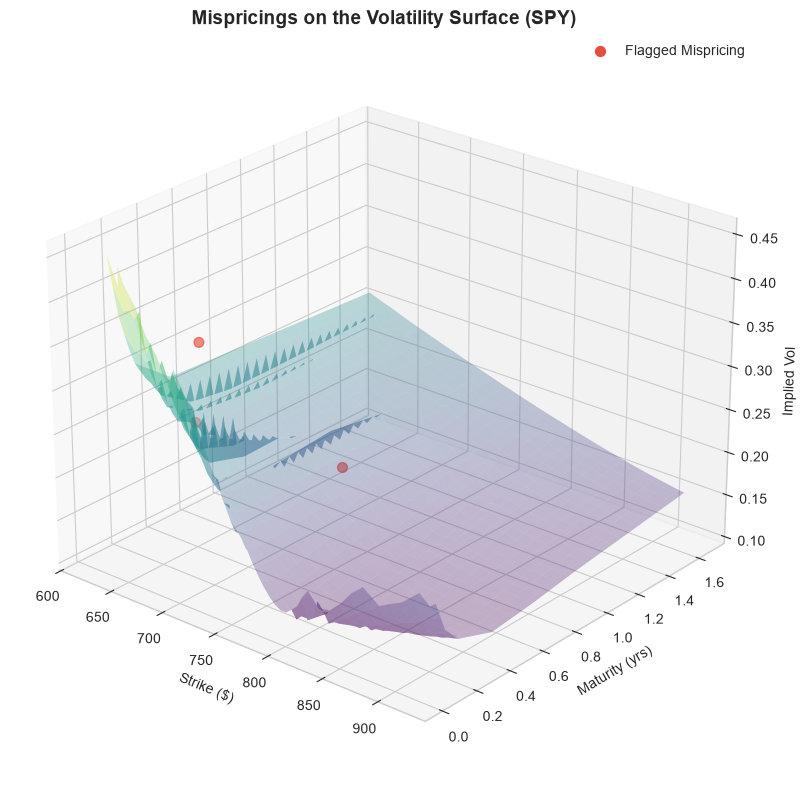

In [32]:
fig = plt.figure(figsize=(12, 8))
ax  = fig.add_subplot(111, projection="3d")

X = calls_valid["strike"].values
Y = calls_valid["maturity"].values
Z = calls_valid["implied_vol"].values
xi = np.linspace(X.min(), X.max(), 60)
yi = np.linspace(Y.min(), Y.max(), 60)
XI, YI = np.meshgrid(xi, yi)
try:
    ZI = griddata((X, Y), Z, (XI, YI), method="linear")
    ax.plot_surface(XI, YI, ZI, cmap=cm.viridis, alpha=0.3,
                    edgecolor="none", antialiased=True)
except Exception:
    pass

if len(misp_df) > 0:
    for T_label in misp_df["Maturity"].unique():
        if T_label in svi_results:
            T_val = svi_results[T_label]["T"]
            sub = misp_df[misp_df["Maturity"] == T_label]
            ax.scatter(sub["Strike"], T_val, sub["Market IV"],
                       s=50, color="#e74c3c", zorder=5, alpha=0.8)

    ax.scatter([], [], [], s=50, color="#e74c3c", label="Flagged Mispricing")
    ax.legend(fontsize=10, loc="upper right")

ax.set_xlabel("Strike ($)")
ax.set_ylabel("Maturity (yrs)")
ax.set_zlabel("Implied Vol")
data_label = "SPY" if USE_REAL_DATA else "Synthetic"
ax.set_title(f"Mispricings on the Volatility Surface ({data_label})",
             fontsize=14, fontweight="bold")
ax.view_init(elev=25, azim=-50)
fig.tight_layout()
plt.show()

### Mispricing & Parity Results

* **Model vs market**: only **3 of 753** call quotes break the 2-vol-point / $1 thresholds, all deep in-the-money calls:
  * 160d, $644 strike: market 23.2% vs SVI 25.7% (cheap by $2.18)
  * 160d, $649 strike: market 32.7% vs SVI 25.2% (rich by $8.49)
  * 251d, $744 strike: market 20.1% vs SVI 18.5% (rich by $3.71)

  Two neighbouring strikes deviating in opposite directions points to stale or wide quotes, not a tradeable mispricing.
* **Put-call parity**: 224 of 505 call/put pairs miss by more than $1. The misses are mostly positive and nearly constant across strikes within an expiry (median about +$1.06 to +$1.14 at 15–29 days, +$2.97 at 603 days). A constant offset that grows with maturity points to the carry inputs (one 10-year Treasury rate and a flat 1.3% dividend yield for every expiry) rather than to strike-specific arbitrage, with American exercise adding a smaller effect. Inferring the forward for each expiry from the call/put pairs is the standard way to remove this kind of offset.

---
## 11. Conclusions & Extensions

*All figures below come from the run on 21 Oct 2026 (SPY spot $769.05, r = 5.12%, q = 1.30%, 10 expirations from 7 to 603 days, 1,499 quotes). Re-running pulls fresh quotes, so the exact numbers will change.*

### Key Findings

| Topic | Result |
|---|---|
| **Data** | 753 calls and 746 puts passed the liquidity filters; every quote produced a valid IV (11.1%–56.8%, median 17.8%). |
| **Volatility Surface** | Steep put skew at every maturity; a smile with a call-side upturn only up to about 57 days; skew flattens from about 16 vol points (90%–110% strikes, 29d) to about 6 (603d). |
| **Term Structure** | Short inversion (ATM 16.5% at 7d down to 14.6% at 85d), then upward-sloping to 20.0% at 603d. Nelson-Siegel fits about twice as well as a cubic polynomial (RMSE 0.0019 vs 0.0037). |
| **SVI Calibration** | Average RMSE 0.26 vol points; best on long-dated slices (≈0.01 points), worst at 160d (0.97 points, driven by noisy quotes). No calendar or butterfly arbitrage. |
| **SABR Calibration** | Average RMSE 0.42 vol points; loses to SVI at 9 of 10 maturities. Vol-of-vol ν falls from 5.0 (the bound) at 7d to 0.71 at 603d; ρ stays near −0.65. |
| **Greeks** | Gamma is concentrated near spot at the shortest expirations; vega is largest for long-dated near-the-money options (up to ≈$3.86 per vol point). |
| **Delta Hedging** | Daily hedging of a 3-month ATM call: mean P&L −$0.03 (≈0), std $2.04 with a longer left tail. Std rises to $2.79 (every 2 days) and $4.42 (weekly), in line with √(rebalance interval). |
| **Vol Risk Premium** | ATM implied vol exceeds the 12.71% 1-year realized vol at every maturity: +1.93 to +7.25 points, average +3.55. |
| **Mispricings** | Only 3 of 753 call quotes are flagged, all deep in-the-money calls with likely stale or wide quotes. |
| **Put-Call Parity** | 224 of 505 pairs miss by more than $1; the near-constant offset that grows with maturity points to the flat rate and dividend inputs plus American exercise, not to arbitrage. |

### Model Assessment

* **SVI is the better fit for this surface.** It is more flexible per slice, arbitrage-free on this data, and far more accurate at the short end, where the SPY smile is steepest.
* **SABR's strength is interpretability.** Its parameters tell a clean story (a stable spot-vol correlation and a vol-of-vol that fades with maturity), but with β fixed at 0.5 it cannot bend enough to match very short smiles. Freeing β, or giving the parameters a term structure, are the natural next steps.
* **Input quality matters as much as the model.** The worst SVI fit, every flagged mispricing and most parity misses trace back to data issues (wide quotes, flat carry inputs) rather than model failure.

### Practical Applications

* **Market Making**: Use the calibrated SVI surface to quote fair prices on illiquid strikes and to screen out bad quotes such as the 160d $644/$649 pair.
* **Risk Management**: The Greeks surfaces show where risk is concentrated: gamma in short-dated near-the-money options, vega in long-dated ones.
* **Volatility Trading**: The persistent gap between implied and realized vol (+3.55 points on average) is the edge behind systematic option-selling strategies, and the hedging simulation shows the P&L noise that comes with it.
* **Relative Value**: The upward-sloping term structure and the flattening skew make calendar spreads and skew trades the natural ways to express a view on this surface.

### Extensions

1. **Implied Forwards** — Infer the forward price and discount factor for each expiry from put-call parity instead of using one 10-year rate and a flat dividend yield.
2. **Local Volatility** — Dupire's formula: $\sigma_{\text{loc}}^2(K,T) = \dfrac{\partial w / \partial T}{1 - \frac{k}{w}\frac{\partial w}{\partial k} + \frac{1}{4}\left(-\frac{1}{4} - \frac{1}{w} + \frac{k^2}{w^2}\right)\left(\frac{\partial w}{\partial k}\right)^2 + \frac{1}{2}\frac{\partial^2 w}{\partial k^2}}$
3. **Heston Stochastic Vol** — Fit the characteristic function via FFT option pricing.
4. **Rough Volatility** — Replace BM driver with fractional BM ($H \approx 0.1$) for better short-term dynamics.
5. **Jump-Diffusion** — Merton or Kou models to capture extreme moves.
6. **ML Surfaces** — Neural-network interpolation of the vol surface with no-arbitrage constraints.

---
*Notebook uses real SPY market data via `yfinance` when available; synthetic fallback ensures full reproducibility.*